<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/reddit_posts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reddit Posts

In [10]:
from pathlib import Path
import runpy

ROOT = Path("/content/rhetorical_signatures")
_INITIALIZER = ROOT / "code" / "initialize_experiment.py"
if not _INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")

# run_path returns the variables defined by the initialization script;
# publish them to notebook globals for compatibility with cells 02 onward.
globals().update(runpy.run_path(str(_INITIALIZER)))


Environment ready
-------------------------------------------------------
Python: 3.13.18
PyTorch: 2.14.1+cpu
CUDA available: False
spaCy: 3.8.18

Dataset selection
-------------------------------------------------------
Selection algorithm version: 2
Sampling: proportional
Sentence range: 10–10
Number of bins: 10
Seed: 42
Include Human: True

RST parsing
-------------------------------------------------------
Number of sentences: 10
Matched: False
Model: tchewik/isanlp_rst_v3
Model version: rstdt
Device: auto
Document limit: None
Retry errors: False

XML forests
-------------------------------------------------------
Grouping variables: ['genre', 'source', 'n_sentences']
Rebuild: False
Validate: True
External metadata: None

TreeRePair compression
-------------------------------------------------------
Genre: reddit
Sentences: 10
Sources: None
Rebuild: False
Textual grammar: True
Optimization: filesize
Max rank: None
Timeout: 600s

TreeDePair validation
------------------------------

In [11]:
# ------------------------------------------------------------
# RAID dataset availability
# ------------------------------------------------------------

raid_downloader = load_project_module(
    "raid_downloader",
    PROCESSING_DIR / "01_download_raid.py",
)

raid_downloader.download_raid()

RAID dataset already available: /content/rhetorical_signatures/data/raw/raid/train.csv


PosixPath('/content/rhetorical_signatures/data/raw/raid/train.csv')

In [12]:
documents, sentences = process_sentences.load_or_analyze_sentence_lengths(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    rebuild=SENTENCE_ANALYSIS_REBUILD,
    show_progress=SENTENCE_ANALYSIS_SHOW_PROGRESS,
)

sentence_stats = sentences.merge(
    documents[["id", "source"]],
    on="id",
    how="left",
    validate="many_to_one",
)

assert sentence_stats["source"].notna().all()

print(
    f"{len(documents):,} documents | "
    f"{len(sentences):,} sentences | "
    f"{documents['source'].nunique()} sources"
)

Loaded existing sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no
12,453 documents | 174,403 sentences | 7 sources


In [13]:
source_order = [
    source for source in MODEL_ORDER
    if source in documents["source"].unique()
]

document_summary = (
    documents.groupby("source")
    .agg(
        documents=("id", "size"),
        median_sentences=("n_sentences", "median"),
        mean_sentences=("n_sentences", "mean"),
        median_words=("n_words", "median"),
        mean_words=("n_words", "mean"),
    )
    .reindex(source_order)
)

sentence_summary = (
    sentence_stats.groupby("source")
    .agg(
        sentences=("id", "size"),
        median_words_per_sentence=("n_words", "median"),
        mean_words_per_sentence=("n_words", "mean"),
    )
    .reindex(source_order)
)

descriptive_summary = document_summary.join(sentence_summary)

display(
    descriptive_summary.style.format({
        "documents": "{:,.0f}",
        "sentences": "{:,.0f}",
        "median_sentences": "{:.1f}",
        "mean_sentences": "{:.1f}",
        "median_words": "{:.1f}",
        "mean_words": "{:.1f}",
        "median_words_per_sentence": "{:.1f}",
        "mean_words_per_sentence": "{:.1f}",
    })
)

,documents,median_sentences,mean_sentences,median_words,mean_words,sentences,median_words_per_sentence,mean_words_per_sentence
source,,,,,,,,
Human,"1,779",10.0,10.3,167.0,178.6,"18,325",15.0,17.3
ChatGPT,"1,779",8.0,9.3,119.0,144.2,"16,546",16.0,15.5
GPT-4,"1,779",14.0,15.0,205.0,209.2,"26,689",13.0,13.9
Mistral 7B,"1,779",29.0,30.0,337.0,335.3,"53,380",10.0,11.2
Mistral 7B (Chat),"1,779",9.0,9.7,141.0,156.1,"17,209",16.0,16.1
Cohere,"1,779",13.0,14.1,206.0,224.3,"25,126",14.0,15.9
Cohere (Chat),"1,779",8.0,9.6,138.0,158.0,"17,128",15.0,16.4


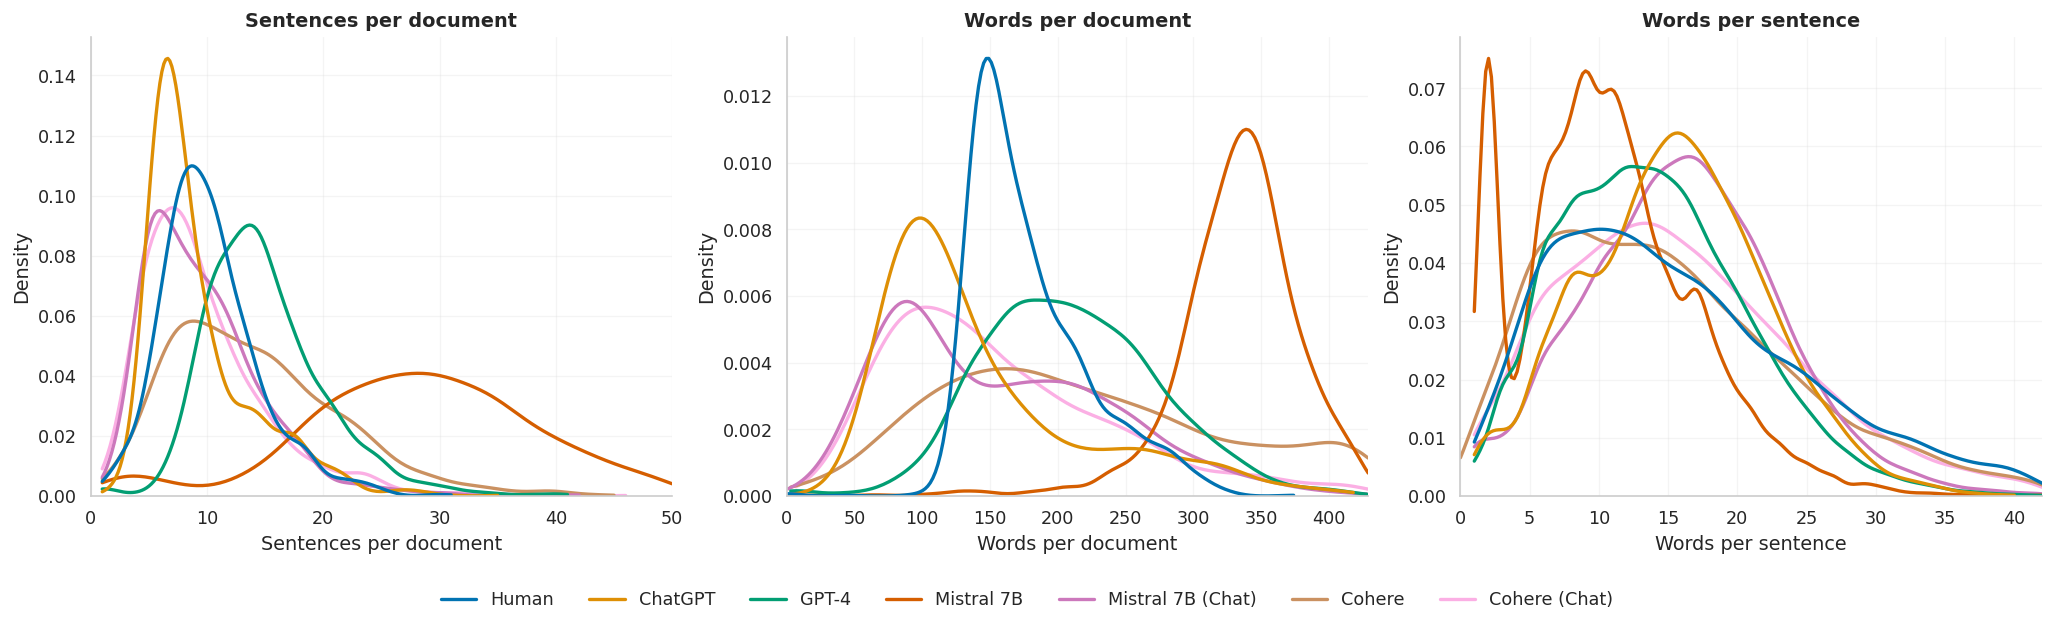

In [14]:

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.6), constrained_layout=True
)

variables = [
    (documents, "n_sentences", "Sentences per document"),
    (documents, "n_words", "Words per document"),
    (sentence_stats, "n_words", "Words per sentence"),
]

palette = dict(zip(
    source_order,
    sns.color_palette("colorblind", n_colors=len(source_order))
))

for ax, (data, column, xlabel) in zip(axes, variables):
    upper = data[column].quantile(0.99)

    subset = data.loc[
        data[column].notna() & data[column].le(upper)
    ].copy()

    sns.kdeplot(
        data=subset,
        x=column,
        hue="source",
        hue_order=source_order,
        palette=palette,
        common_norm=False,
        bw_adjust=1.0,
        cut=0,
        clip=(0, None),
        linewidth=2,
        fill=False,
        warn_singular=False,
        ax=ax,
        legend=False,
    )

    ax.set(
        xlabel=xlabel,
        ylabel="Density",
        title=xlabel,
    )
    ax.set_xlim(left=0, right=upper)
    ax.grid(alpha=0.2)

from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        color=palette[source],
        lw=2,
        label=source,
    )
    for source in source_order
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(source_order), 7),
)

plt.show()

Saved selected dataset: /content/rhetorical_signatures/data/filtered/sentences/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-1__proportional__seed-42__bins-10__human-1
Best n=10; minimum selected LLM documents=57
Saved selected dataset: /content/rhetorical_signatures/data/filtered/sentences/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
Best n=10; minimum selected LLM documents=592
Matched: n=10, 57 documents per source
Unmatched: n=10, 592 documents per source


,selection,source,best_n,eligible,selected
0,Matched,Human,10,922,57
1,Matched,ChatGPT,10,592,57
2,Matched,GPT-4,10,1597,57
3,Matched,Mistral 7B,10,1690,57
4,Matched,Mistral 7B (Chat),10,778,57
5,Matched,Cohere,10,1222,57
6,Matched,Cohere (Chat),10,716,57
7,Unmatched,Human,10,922,592
8,Unmatched,ChatGPT,10,592,592
9,Unmatched,GPT-4,10,1597,592


,selection,source,median_before,median_after,wasserstein
0,Matched,Human,150.0,154.0,4.29
1,Matched,ChatGPT,161.5,158.0,5.50
2,Matched,GPT-4,150.0,148.0,3.28
3,Matched,Mistral 7B,116.0,106.0,7.78
4,Matched,Mistral 7B (Chat),166.0,160.0,6.65
5,Matched,Cohere,157.0,155.0,8.58
6,Matched,Cohere (Chat),156.0,162.0,7.82
7,Unmatched,Human,150.0,150.0,0.54
8,Unmatched,ChatGPT,161.5,161.5,0.00
9,Unmatched,GPT-4,150.0,150.0,0.37


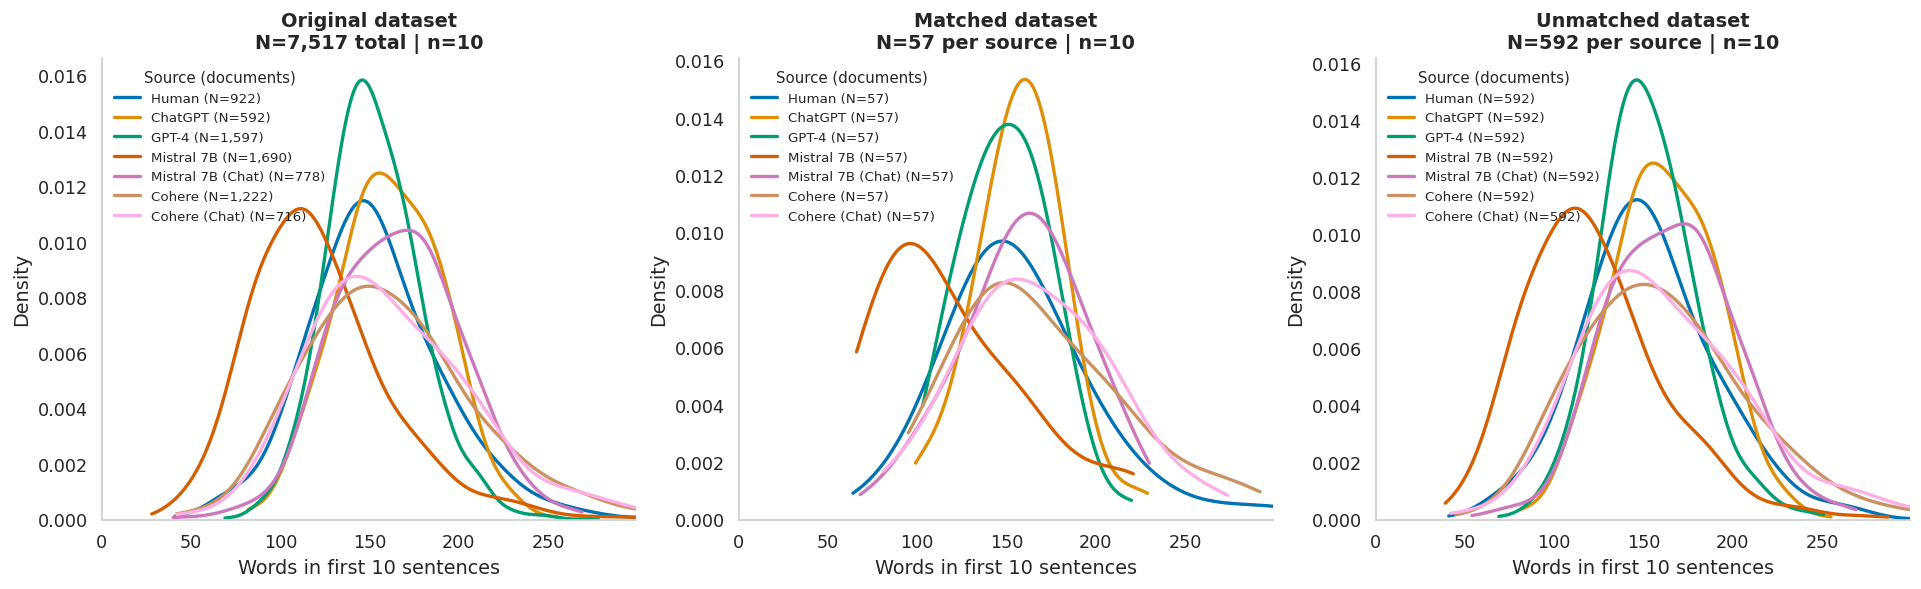

In [15]:
# Selection and diagnostics — no helper definitions in the notebook
selection_kwargs = dict(
    documents=documents, sentences=sentences,
    min_sentences=MIN_SENTENCES, max_sentences=MAX_SENTENCES,
    domain=DOMAIN, prompting=PROMPTING, attack=ATTACK,
    decoding=DECODING, repetition_penalty=REPETITION_PENALTY,
    sampling=SAMPLING, n_bins=N_BINS, seed=SEED,
    include_human=INCLUDE_HUMAN,
)

selected_matched, comparison_matched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=True
    )
)
selected_unmatched, comparison_unmatched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=False
    )
)

count_summary, distribution_check = process_sentences.selection_diagnostics(
    documents, sentences,
    {
        'Matched': (selected_matched, comparison_matched),
        'Unmatched': (selected_unmatched, comparison_unmatched),
    },
)


### Parsing

In [16]:

# ============================================================
# 02 — Load or parse first 200 RST trees per source
# ============================================================

output, trees, limited_trees_file = (
    rst.load_or_parse_first_per_source(
        domain=DOMAIN,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        min_sentences=MIN_SENTENCES,
        max_sentences=MAX_SENTENCES,
        n_sentences=N_SENTENCES,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        seed=SEED,
        n_bins=N_BINS,
        include_human=INCLUDE_HUMAN,
        model=RST_MODEL,
        model_version=RST_MODEL_VERSION,
        device=RST_DEVICE,
        retry_errors=RST_RETRY_ERRORS,
        output_root=RST_DATA_DIR,
        max_per_source=200,
    )
)

print(f"RST trees loaded: {len(trees)}")
print(f"Output: {output}")

RST cache: 1400/4144 successful; 0 previous failures; 0 to parse


RST parsing (n=10): 0it [00:00, ?it/s]

Loaded existing dataset: /content/rhetorical_signatures/data/filtered/sentences/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
RST output: /content/rhetorical_signatures/data/rst/unmatched/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
RST trees selected per source:
  ChatGPT: 200
  Cohere: 200
  Cohere (Chat): 200
  GPT-4: 200
  Human: 200
  Mistral 7B: 200
  Mistral 7B (Chat): 200
Total selected: 1400
Full cache: /content/rhetorical_signatures/data/rst/unmatched/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/trees.jsonl
Forest input: /content/rhetorical_signatures/data/rst/unmatched/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-1

### Build forests

In [17]:

# ============================================================
# 03 — Build XML forests (200 RST trees per source)
# ============================================================

(
    forests_dir,
    forest_paths,
    forest_index,
    manifest,
) = forest_builder.load_or_build_forests(
    trees_file=limited_trees_file,
    metadata_file=FOREST_METADATA_FILE,
    group_by=FOREST_GROUP_BY,
    rebuild=True,
    validate=FOREST_VALIDATE,
)

print(f"XML forests created: {len(forest_paths)}")
print(f"Forests directory: {forests_dir}")

Rebuilding XML forests...
[1/7] 0001__genre-reddit__source-ChatGPT__n_sentences-10.xml: 200 trees
[2/7] 0002__genre-reddit__source-Cohere__n_sentences-10.xml: 200 trees
[3/7] 0003__genre-reddit__source-Cohere_Chat__n_sentences-10.xml: 200 trees
[4/7] 0004__genre-reddit__source-GPT-4__n_sentences-10.xml: 200 trees
[5/7] 0005__genre-reddit__source-Human__n_sentences-10.xml: 200 trees
[6/7] 0006__genre-reddit__source-Mistral_7B__n_sentences-10.xml: 200 trees
[7/7] 0007__genre-reddit__source-Mistral_7B_Chat__n_sentences-10.xml: 200 trees

FOREST GENERATION COMPLETE
RST trees: 1400
XML forests: 7
Output: /content/rhetorical_signatures/data/rst/unmatched/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/forests

XML FORESTS READY
Forests: 7
RST trees: 1400
Directory: /content/rhetorical_signatures/data/rst/unmatched/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10_

# TreeRePair

In [18]:
# ============================================================
# 04 — TreeRePair grammar compression (500 trees per source)
# ============================================================

compression_dir, compression_results, compression_manifest = (
    tree_compressor.run_treerepair(
        forests_dir=forests_dir,
        binary=TREEREPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=True,
        textual=COMPRESSION_TEXTUAL,
        optimize=COMPRESSION_OPTIMIZE,
        max_rank=COMPRESSION_MAX_RANK,
        timeout=COMPRESSION_TIMEOUT,
        continue_on_error=COMPRESSION_CONTINUE_ON_ERROR,
    )
)

compression_summary = pd.DataFrame(compression_results)

display(compression_summary)

[1/7] ChatGPT
  COMPLETED_UNVALIDATED (returncode=0)
[2/7] Cohere
  COMPLETED_UNVALIDATED (returncode=0)
[3/7] Cohere_Chat
  COMPLETED_UNVALIDATED (returncode=0)
[4/7] GPT-4
  COMPLETED_UNVALIDATED (returncode=0)
[5/7] Human
  COMPLETED_UNVALIDATED (returncode=0)
[6/7] Mistral_7B
  COMPLETED_UNVALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  COMPLETED_UNVALIDATED (returncode=0)


,source,forest,status,returncode,cached,rep_file,reptxt_file,rep_bytes,reptxt_bytes,forest_sha256
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5825,25451,86cf748abc12349c46d6dd77855e5364fd0867c0086c1a...
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6461,28578,6792c88a9924f1cc52dfa65a1ea09103fe6844bdc3b061...
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6324,27767,841f71ab1184aaa23b248fe839e5d17bb13d3c66e3c398...
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5782,25114,77ec9d9a73ec4e57c7e0c8ae5d47fa15b7d491c601ac28...
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6356,28001,2a744e8d9a2ae1551c45a3f93aeafcbdfaf1d5f4ed046e...
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,4261,17955,7269558205c97cc80fad3729bef94d38abc1dc3f7818f3...
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5873,25629,236f29ee6084db8af369957ea44fb54570d6d34e0ce00d...


In [19]:

# ============================================================
# 05 — TreeRePair grammar validation
# ============================================================

validation_dir, validation_results, validation_manifest = (
    grammar_validator.validate_grammars(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        binary=TREEDEPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=VALIDATION_REBUILD,
        timeout=VALIDATION_TIMEOUT,
        keep_reconstructed=VALIDATION_KEEP_RECONSTRUCTED,
    )
)

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)


[1/7] ChatGPT
  VALIDATED (returncode=0)
[2/7] Cohere
  VALIDATED (returncode=0)
[3/7] Cohere_Chat
  VALIDATED (returncode=0)
[4/7] GPT-4
  VALIDATED (returncode=0)
[5/7] Human
  VALIDATED (returncode=0)
[6/7] Mistral_7B
  VALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  VALIDATED (returncode=0)


,source,forest,rep_file,restored_file,cached,returncode,original_trees,reconstructed_trees,document_ids_match,structure_match,original_root,reconstructed_root,validated,status
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED


### Extract Motifs

In [20]:
# CELL 06 — Extract RST motifs

motifs_dir, motif_results, motif_manifest = (
    motif_extractor.extract_motifs(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=MOTIF_REBUILD,
        min_relations=MOTIF_MIN_RELATIONS,
        min_depth=MOTIF_MIN_DEPTH,
        include_wildcards=MOTIF_INCLUDE_WILDCARDS,
        continue_on_error=MOTIF_CONTINUE_ON_ERROR,
    )
)

display(pd.DataFrame(motif_results))

print(f"\nMotifs saved to: {motifs_dir}")

[1/7] genre-reddit__n_sentences-10 / ChatGPT
  Cached: 61 motifs
[2/7] genre-reddit__n_sentences-10 / Cohere
  Cached: 22 motifs
[3/7] genre-reddit__n_sentences-10 / Cohere_Chat
  Cached: 23 motifs
[4/7] genre-reddit__n_sentences-10 / GPT-4
  Cached: 25 motifs
[5/7] genre-reddit__n_sentences-10 / Human
  Cached: 41 motifs
[6/7] genre-reddit__n_sentences-10 / Mistral_7B
  Cached: 24 motifs
[7/7] genre-reddit__n_sentences-10 / Mistral_7B_Chat
  Cached: 57 motifs


,dataset,source,status,n_motifs,n_wildcard_motifs,n_grammar_templates,cached,output_dir
0,genre-reddit__n_sentences-10,ChatGPT,COMPLETED,61,18,61,True,/content/rhetorical_signatures/results/sentenc...
1,genre-reddit__n_sentences-10,Cohere,COMPLETED,22,1,22,True,/content/rhetorical_signatures/results/sentenc...
2,genre-reddit__n_sentences-10,Cohere_Chat,COMPLETED,23,1,23,True,/content/rhetorical_signatures/results/sentenc...
3,genre-reddit__n_sentences-10,GPT-4,COMPLETED,25,3,25,True,/content/rhetorical_signatures/results/sentenc...
4,genre-reddit__n_sentences-10,Human,COMPLETED,41,5,41,True,/content/rhetorical_signatures/results/sentenc...
5,genre-reddit__n_sentences-10,Mistral_7B,COMPLETED,24,1,24,True,/content/rhetorical_signatures/results/sentenc...
6,genre-reddit__n_sentences-10,Mistral_7B_Chat,COMPLETED,57,19,57,True,/content/rhetorical_signatures/results/sentenc...



Motifs saved to: /content/rhetorical_signatures/results/sentences_report/motifs/genre-reddit__n_sentences-10


In [21]:
'''
# CELL 07 — Display all motifs, grouped by source
all_motifs = motif_extractor.display_motifs(
    motifs_dir,
    show_grammar_symbols=True,
)
'''

'\n# CELL 07 — Display all motifs, grouped by source\nall_motifs = motif_extractor.display_motifs(\n    motifs_dir,\n    show_grammar_symbols=True,\n)\n'

# INSPECT

Structural analysis: loaded cache from /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


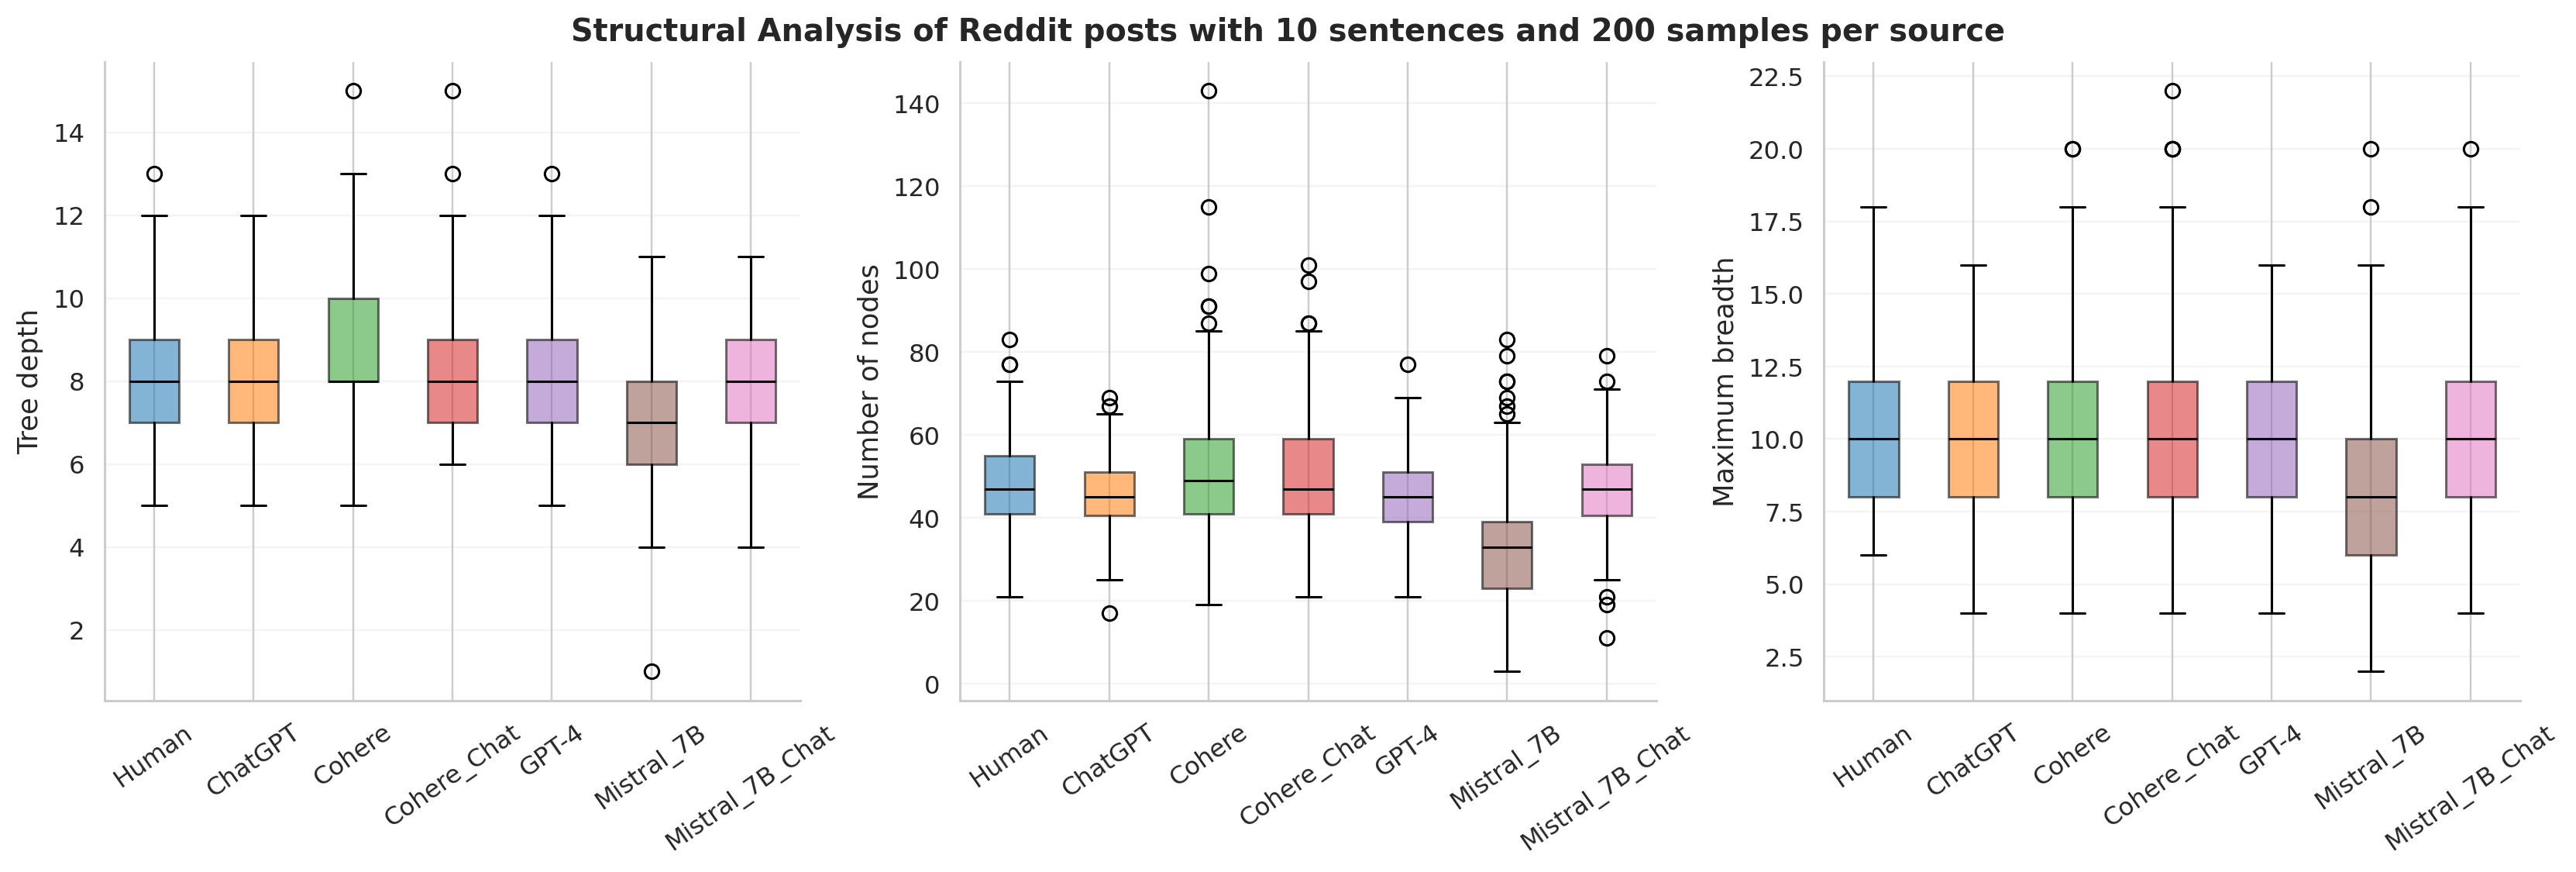

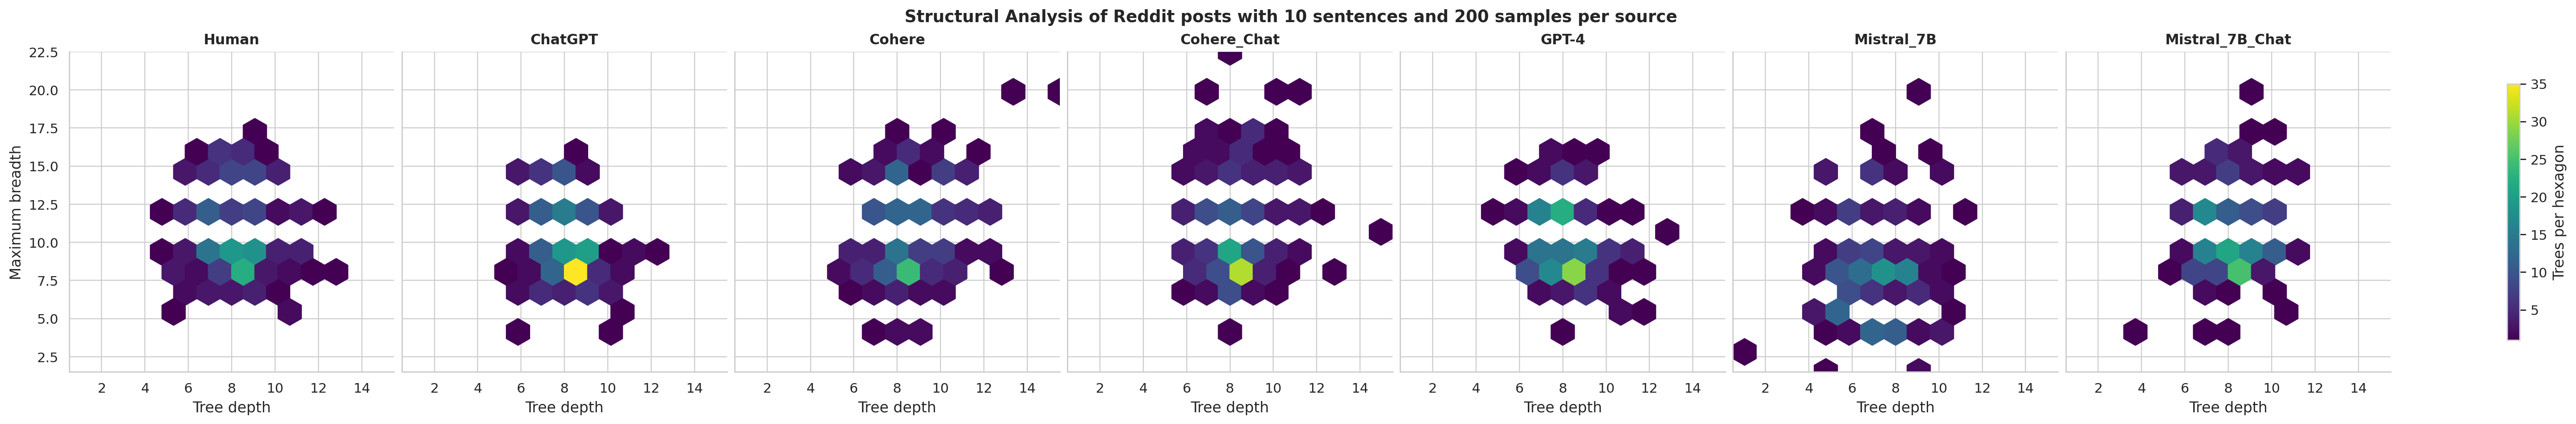

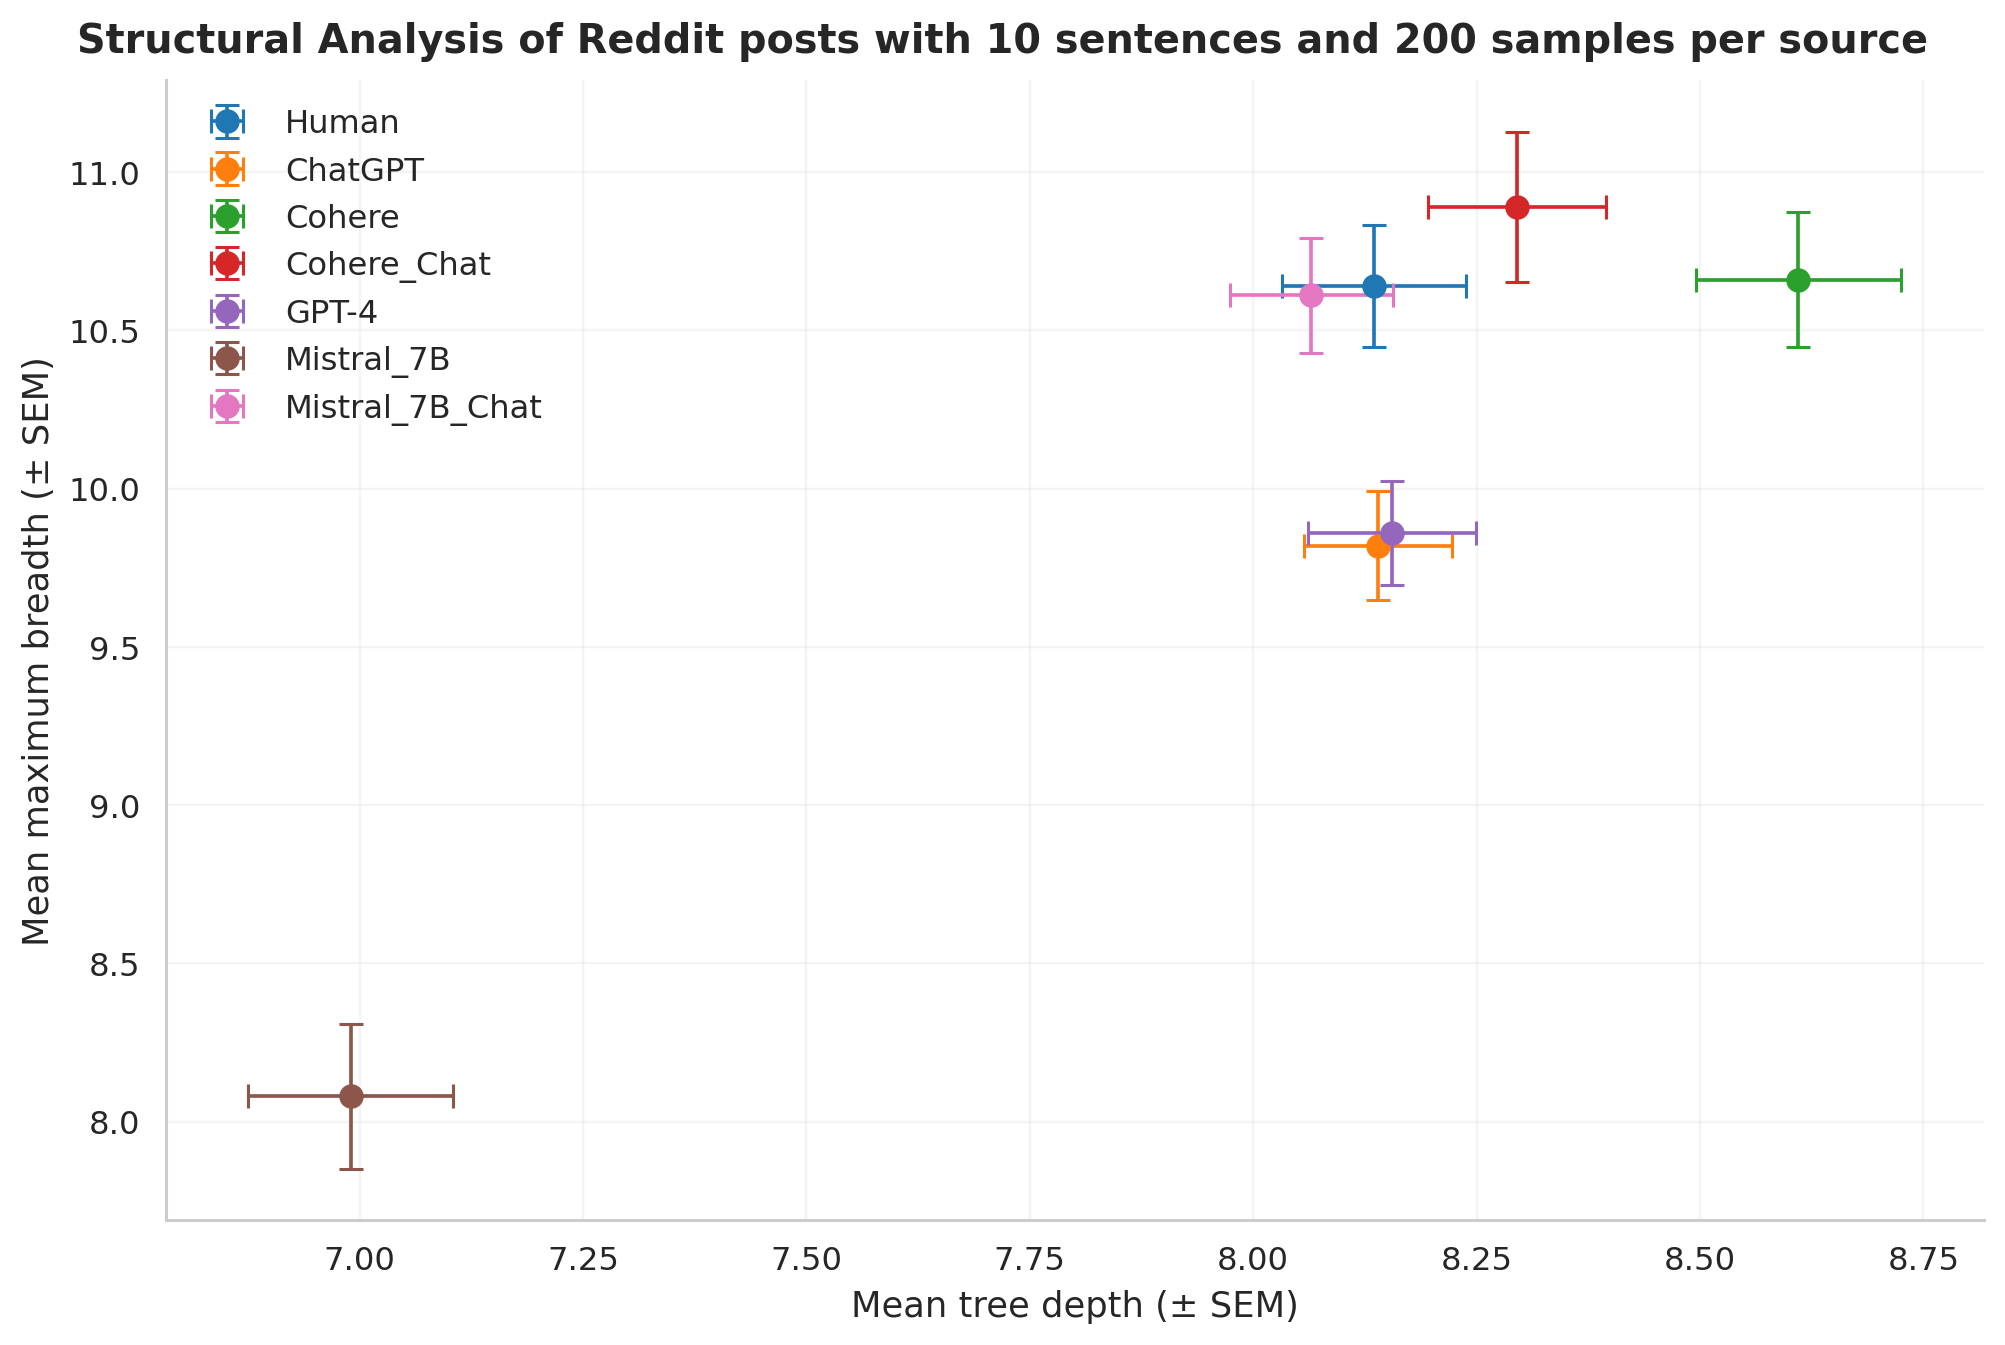

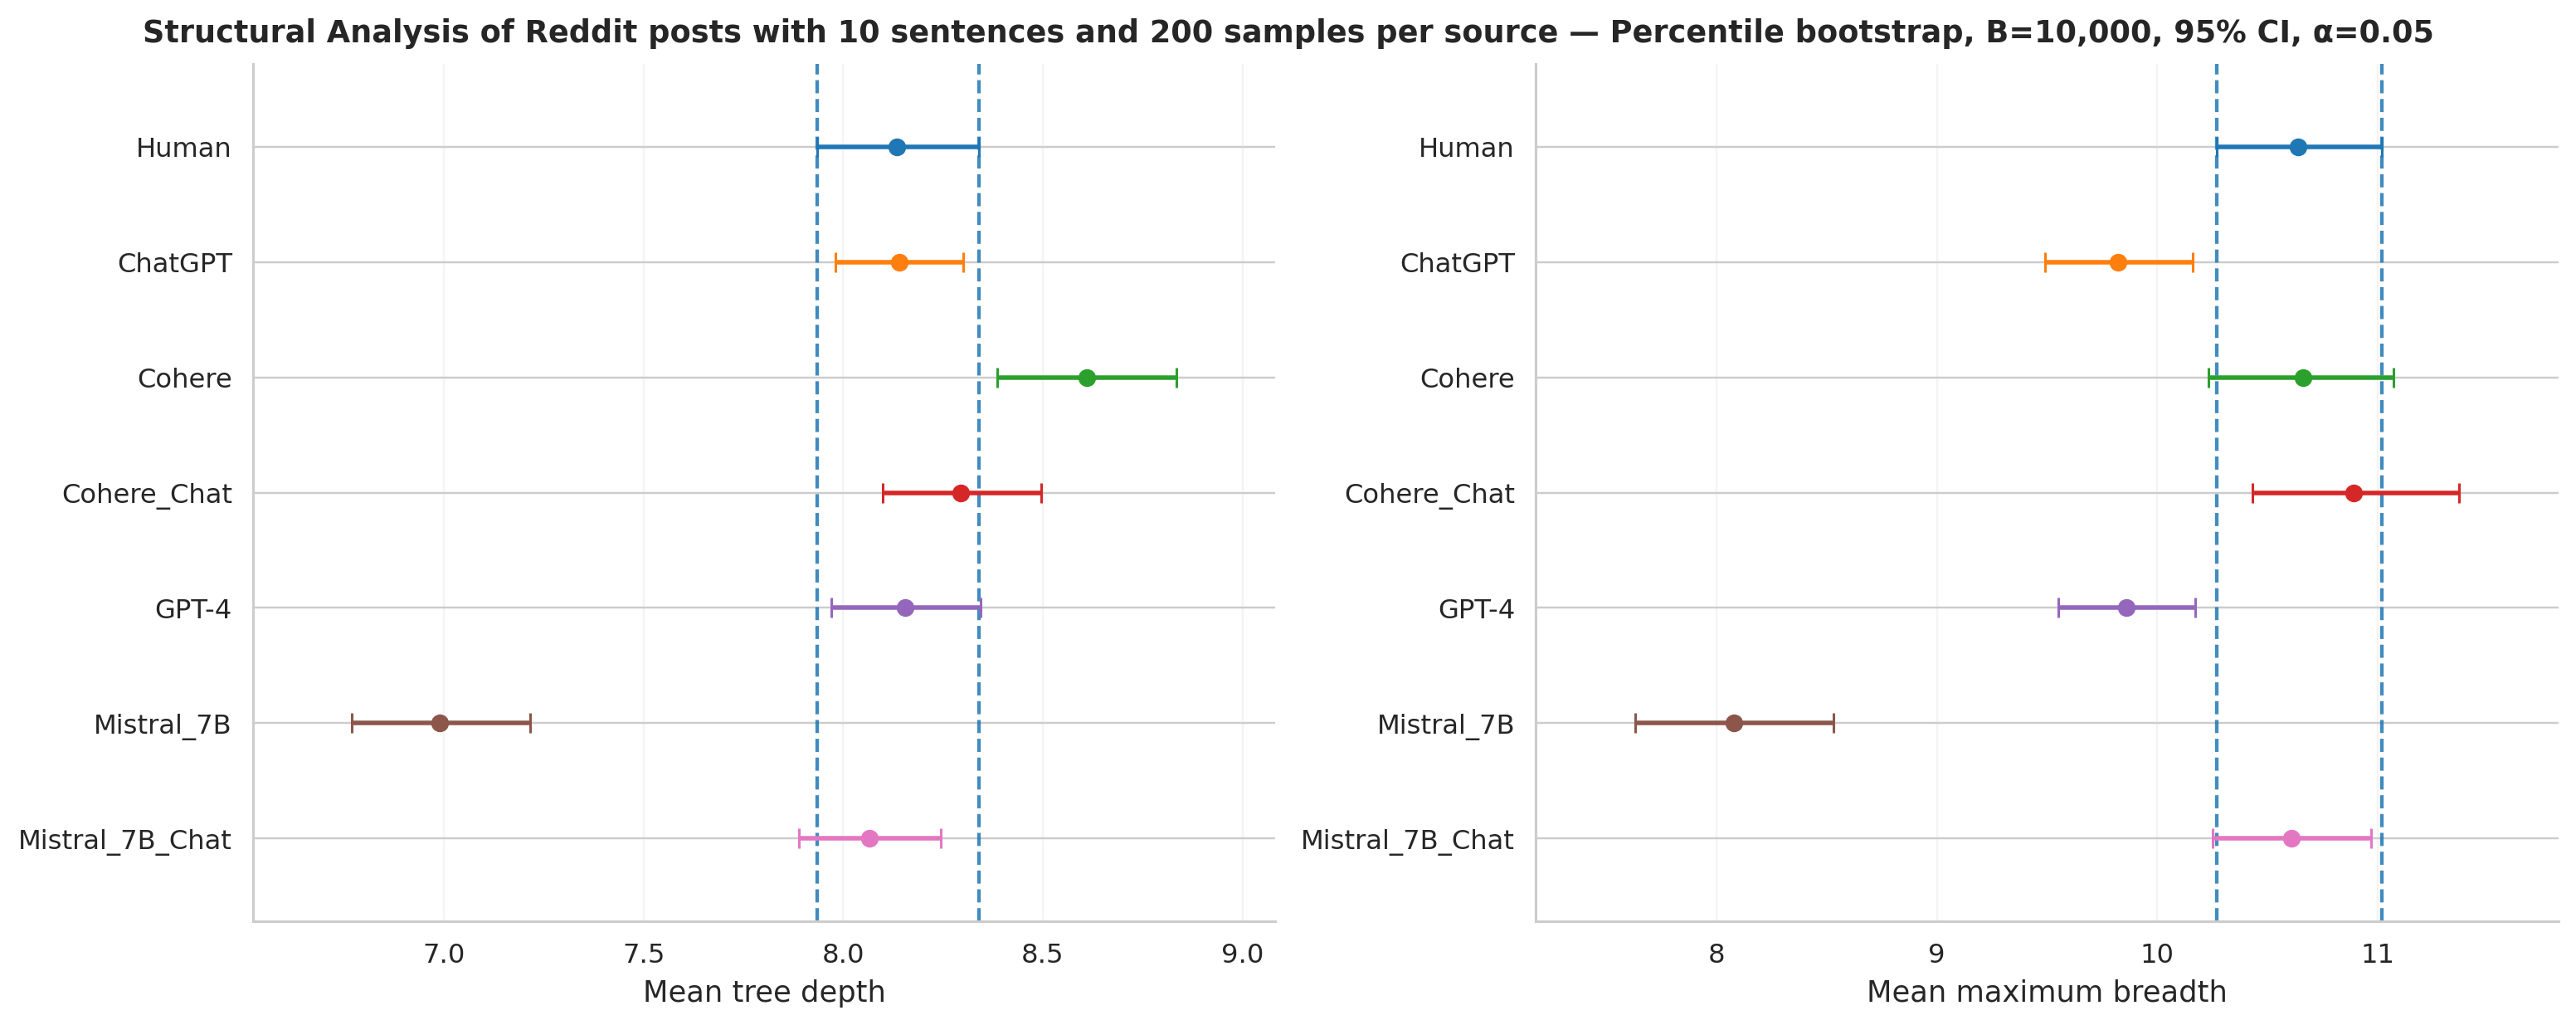

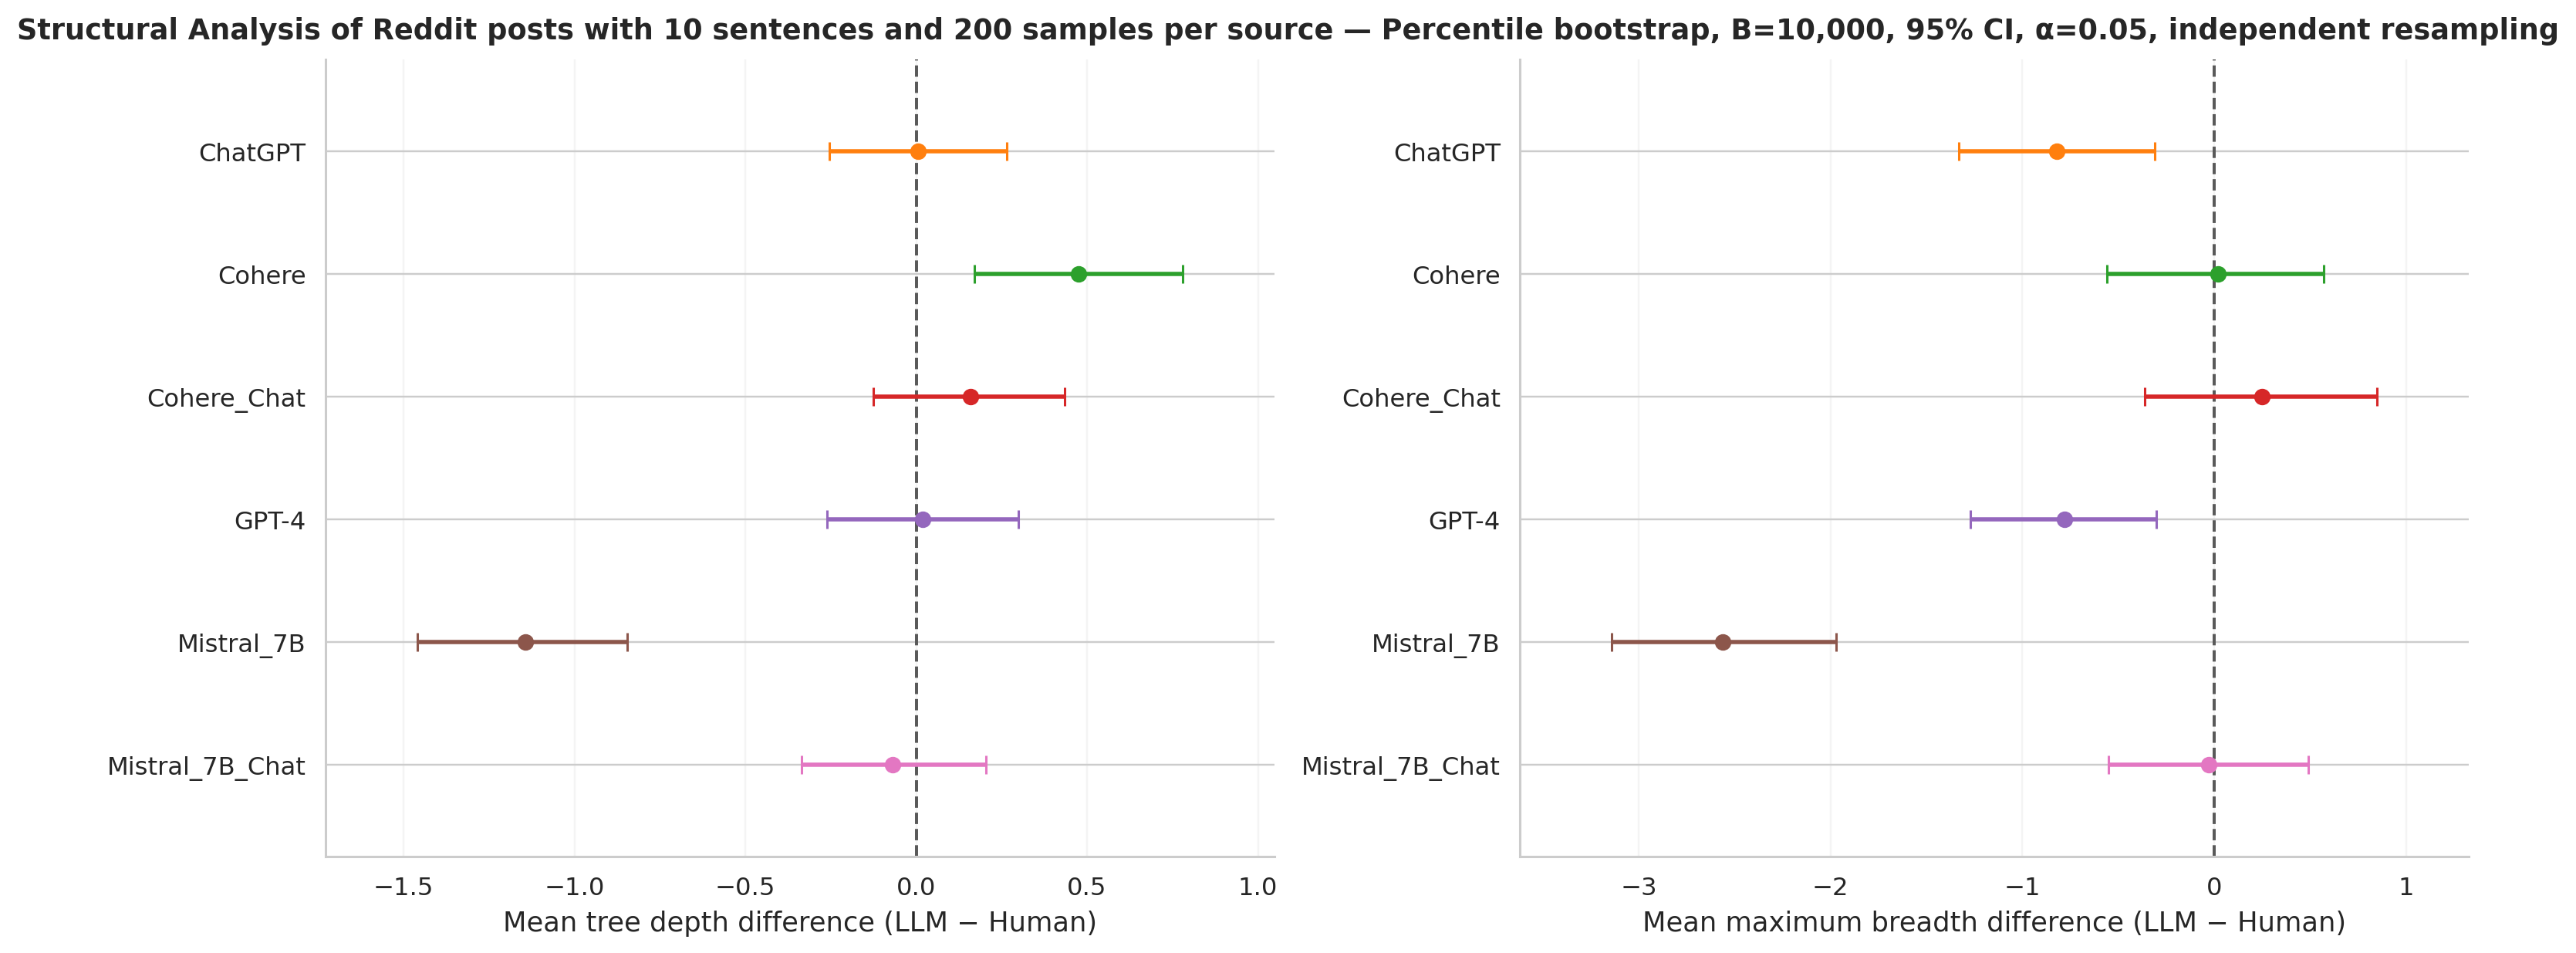


STRUCTURAL SUMMARY — mean ± SD


metric,depth,max_breadth,number_of_nodes
source,,,
ChatGPT,8.14 ± 1.17,9.82 ± 2.42,45.32 ± 8.80
Cohere,8.61 ± 1.63,10.66 ± 3.03,51.20 ± 16.66
Cohere_Chat,8.29 ± 1.41,10.89 ± 3.36,50.39 ± 14.00
GPT-4,8.15 ± 1.33,9.86 ± 2.32,44.72 ± 9.00
Human,8.13 ± 1.46,10.64 ± 2.72,47.59 ± 11.06
Mistral_7B,6.99 ± 1.62,8.08 ± 3.22,34.42 ± 13.82
Mistral_7B_Chat,8.06 ± 1.29,10.61 ± 2.58,46.89 ± 10.28



BOOTSTRAP MEANS — 95% CI


,source,metric,n,mean,ci_low,ci_high,confidence
0,ChatGPT,depth,200,8.140,7.980,8.300,0.95
1,ChatGPT,max_breadth,200,9.820,9.490,10.160,0.95
2,Cohere,depth,200,8.610,8.385,8.835,0.95
3,Cohere,max_breadth,200,10.660,10.230,11.070,0.95
4,Cohere_Chat,depth,200,8.295,8.100,8.495,0.95
5,Cohere_Chat,max_breadth,200,10.890,10.430,11.370,0.95
6,GPT-4,depth,200,8.155,7.970,8.345,0.95
7,GPT-4,max_breadth,200,9.860,9.550,10.170,0.95
8,Human,depth,200,8.135,7.935,8.340,0.95
9,Human,max_breadth,200,10.640,10.270,11.020,0.95



BOOTSTRAP DELTAS — LLM minus Human


,source,reference,metric,n_source,n_reference,delta,ci_low,ci_high,excludes_zero,confidence,bootstrap_method
0,ChatGPT,Human,depth,200,200,0.005,-0.255,0.265,False,0.95,independent
1,ChatGPT,Human,max_breadth,200,200,-0.820,-1.330,-0.310,True,0.95,independent
2,Cohere,Human,depth,200,200,0.475,0.170,0.780,True,0.95,independent
3,Cohere,Human,max_breadth,200,200,0.020,-0.560,0.570,False,0.95,independent
4,Cohere_Chat,Human,depth,200,200,0.160,-0.125,0.435,False,0.95,independent
5,Cohere_Chat,Human,max_breadth,200,200,0.250,-0.360,0.850,False,0.95,independent
6,GPT-4,Human,depth,200,200,0.020,-0.260,0.300,False,0.95,independent
7,GPT-4,Human,max_breadth,200,200,-0.780,-1.270,-0.300,True,0.95,independent
8,Mistral_7B,Human,depth,200,200,-1.145,-1.460,-0.845,True,0.95,independent
9,Mistral_7B,Human,max_breadth,200,200,-2.560,-3.140,-1.970,True,0.95,independent



Results saved to: /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [22]:

# ============================================================
# 07 — RST structural analysis
# ============================================================

# Unique dataset identifier:
# experiment filters + sentence selection + tree subset
structural_dataset_name = (
    f"{run_name}__{Path(output).name}"
    f"__{STRUCTURAL_TREE_SET}"
)

structural_dir, structural_results = (
    structural_inspector.inspect_rst_trees(
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=STRUCTURAL_SOURCES,
        dataset_name=structural_dataset_name,
        n_boot=STRUCTURAL_N_BOOT,
        confidence=STRUCTURAL_CONFIDENCE,
        seed=STRUCTURAL_SEED,
        human_source=STRUCTURAL_HUMAN_SOURCE,
        delta_method=STRUCTURAL_DELTA_METHOD,
        hex_gridsize=STRUCTURAL_HEX_GRIDSIZE,
        rebuild=STRUCTURAL_REBUILD,
        show=STRUCTURAL_SHOW,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,

    )
)

# ------------------------------------------------------------
# Compact statistical reports
# ------------------------------------------------------------

print("\nSTRUCTURAL SUMMARY — mean ± SD")

summary = structural_results["summary"].copy()
summary["mean_sd"] = summary.apply(
    lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}",
    axis=1,
)

display(
    summary.pivot(
        index="source",
        columns="metric",
        values="mean_sd",
    )
)

print("\nBOOTSTRAP MEANS — 95% CI")
display(structural_results["bootstrap_means"].round(3))

print("\nBOOTSTRAP DELTAS — LLM minus Human")
display(structural_results["bootstrap_deltas"].round(3))

print(f"\nResults saved to: {structural_dir}")

Recounting all 68 motifs in ChatGPT: 0001__genre-reddit__source-ChatGPT__n_sentences-10.xml
Recounting all 68 motifs in Cohere: 0002__genre-reddit__source-Cohere__n_sentences-10.xml
Recounting all 68 motifs in Cohere_Chat: 0003__genre-reddit__source-Cohere_Chat__n_sentences-10.xml
Recounting all 68 motifs in GPT-4: 0004__genre-reddit__source-GPT-4__n_sentences-10.xml
Recounting all 68 motifs in Human: 0005__genre-reddit__source-Human__n_sentences-10.xml
Recounting all 68 motifs in Mistral_7B: 0006__genre-reddit__source-Mistral_7B__n_sentences-10.xml
Recounting all 68 motifs in Mistral_7B_Chat: 0007__genre-reddit__source-Mistral_7B_Chat__n_sentences-10.xml


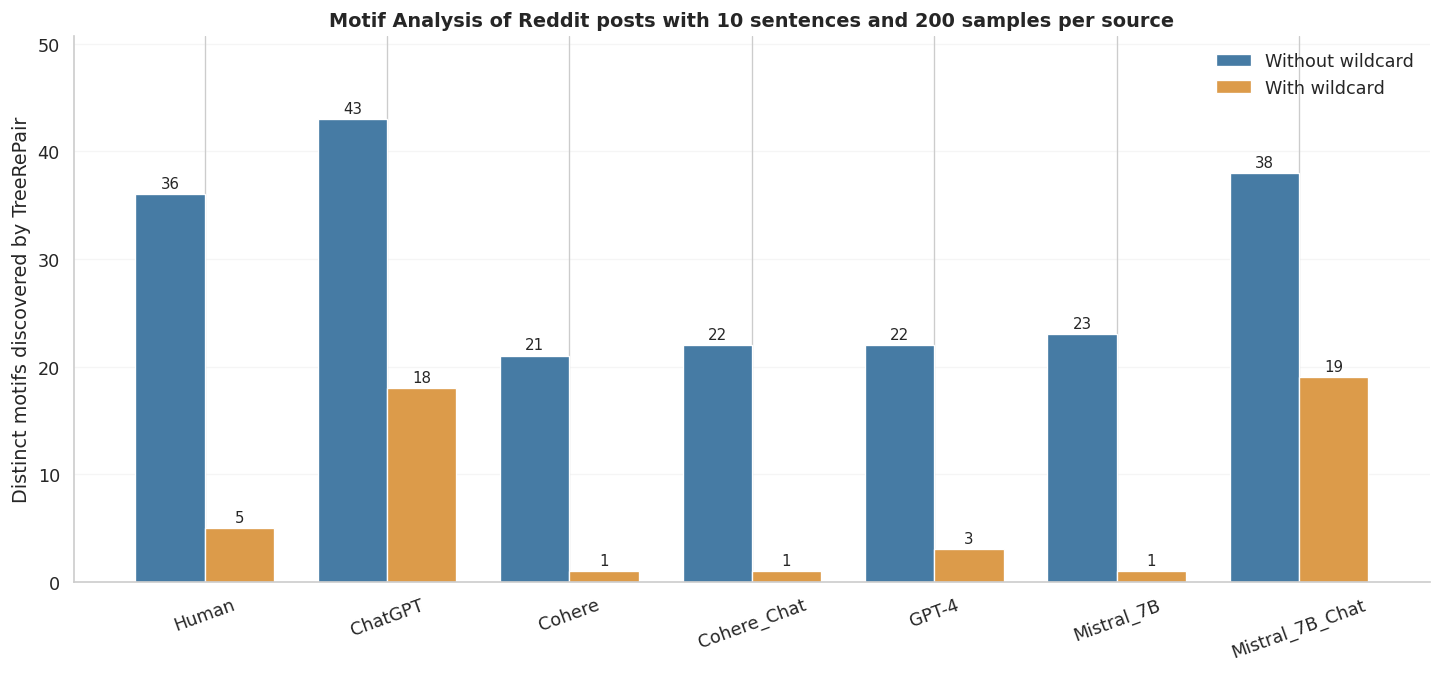

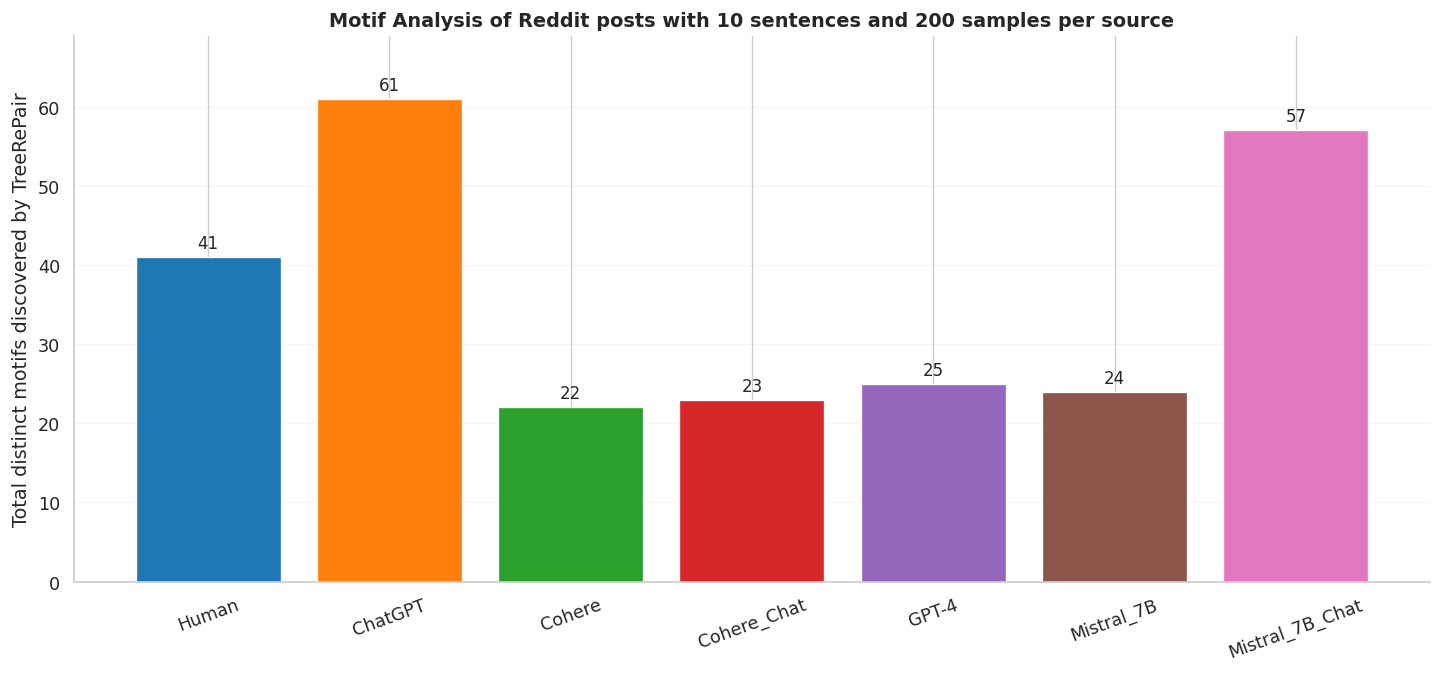

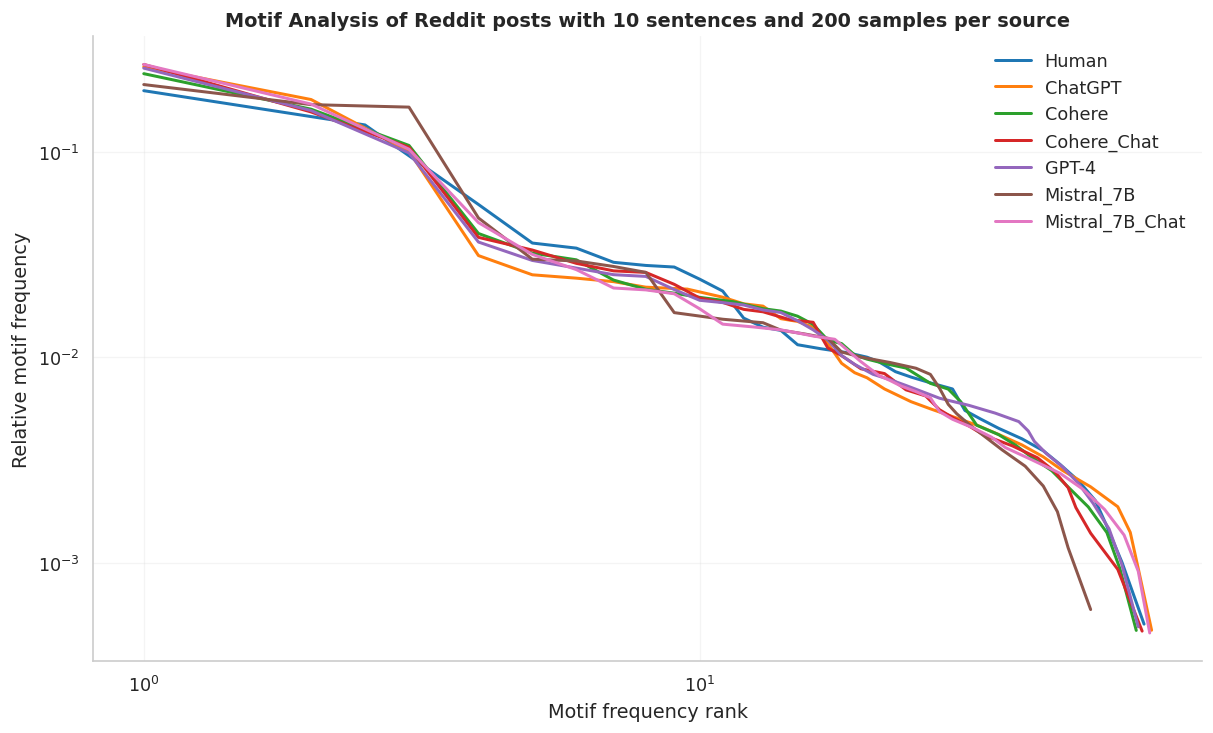

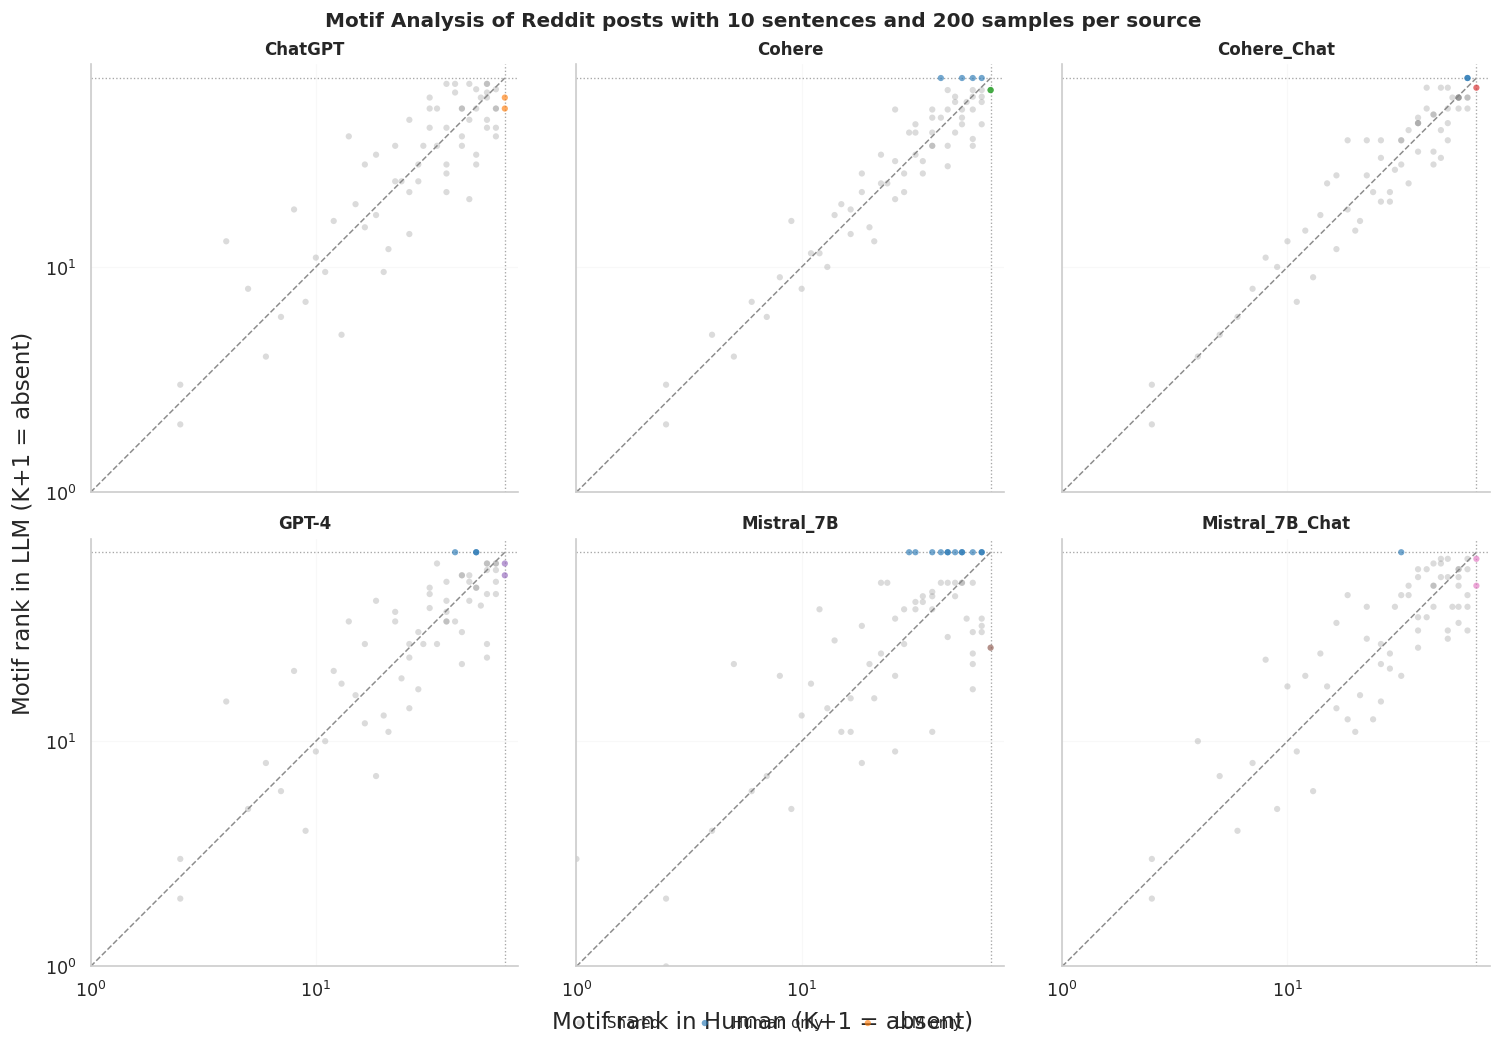

Saved 68 unique motifs and 1400 documents to /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
JSD comparisons sorted descending; wildcard motifs excluded from JSD and ranks.
motif_document_frequencies.csv explicitly includes zero counts.
Jensen–Shannon divergence: Human vs LLM


,llm_source,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,Mistral_7B,0.0798,0.0785,0.1219,0.95,10000,10000,200,200
1,Mistral_7B_Chat,0.0458,0.0461,0.0722,0.95,10000,10000,200,200
2,GPT-4,0.0456,0.0458,0.0702,0.95,10000,10000,200,200
3,ChatGPT,0.0435,0.0433,0.0693,0.95,10000,10000,200,200
4,Cohere,0.0228,0.0260,0.0445,0.95,10000,10000,200,200
5,Cohere_Chat,0.0199,0.0227,0.0430,0.95,10000,10000,200,200


Jensen–Shannon divergence: LLM vs LLM


,source_a,source_b,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,Cohere,Mistral_7B,0.0936,0.0893,0.1361,0.95,10000,10000,200,200
1,GPT-4,Mistral_7B,0.0895,0.0852,0.1334,0.95,10000,10000,200,200
2,Cohere_Chat,Mistral_7B,0.0891,0.0841,0.1336,0.95,10000,10000,200,200
3,ChatGPT,Mistral_7B,0.0879,0.0845,0.1308,0.95,10000,10000,200,200
4,Mistral_7B,Mistral_7B_Chat,0.0842,0.0795,0.1299,0.95,10000,10000,200,200
5,Cohere,Mistral_7B_Chat,0.0352,0.0367,0.0585,0.95,10000,10000,200,200
6,Cohere_Chat,GPT-4,0.0302,0.0321,0.0528,0.95,10000,10000,200,200
7,Cohere_Chat,Mistral_7B_Chat,0.0265,0.0296,0.0491,0.95,10000,10000,200,200
8,GPT-4,Mistral_7B_Chat,0.0265,0.0297,0.0492,0.95,10000,10000,200,200
9,Cohere,GPT-4,0.0264,0.0285,0.0490,0.95,10000,10000,200,200


Results saved to: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [23]:

# ============================================================
# CELL 08 — Motif divergence analysis
# ============================================================

divergence_dir, divergence_results = (
    divergence_analyzer.analyze_motif_divergence(
        motifs_dir=motifs_dir,
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        dataset_name=structural_dataset_name,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        top_k=100,
        rebuild=False,
        show=True,
    )
)


divergence_analyzer.display_js_tables(
    divergence_results,
    decimals=4
)

print(f"Results saved to: {divergence_dir}")

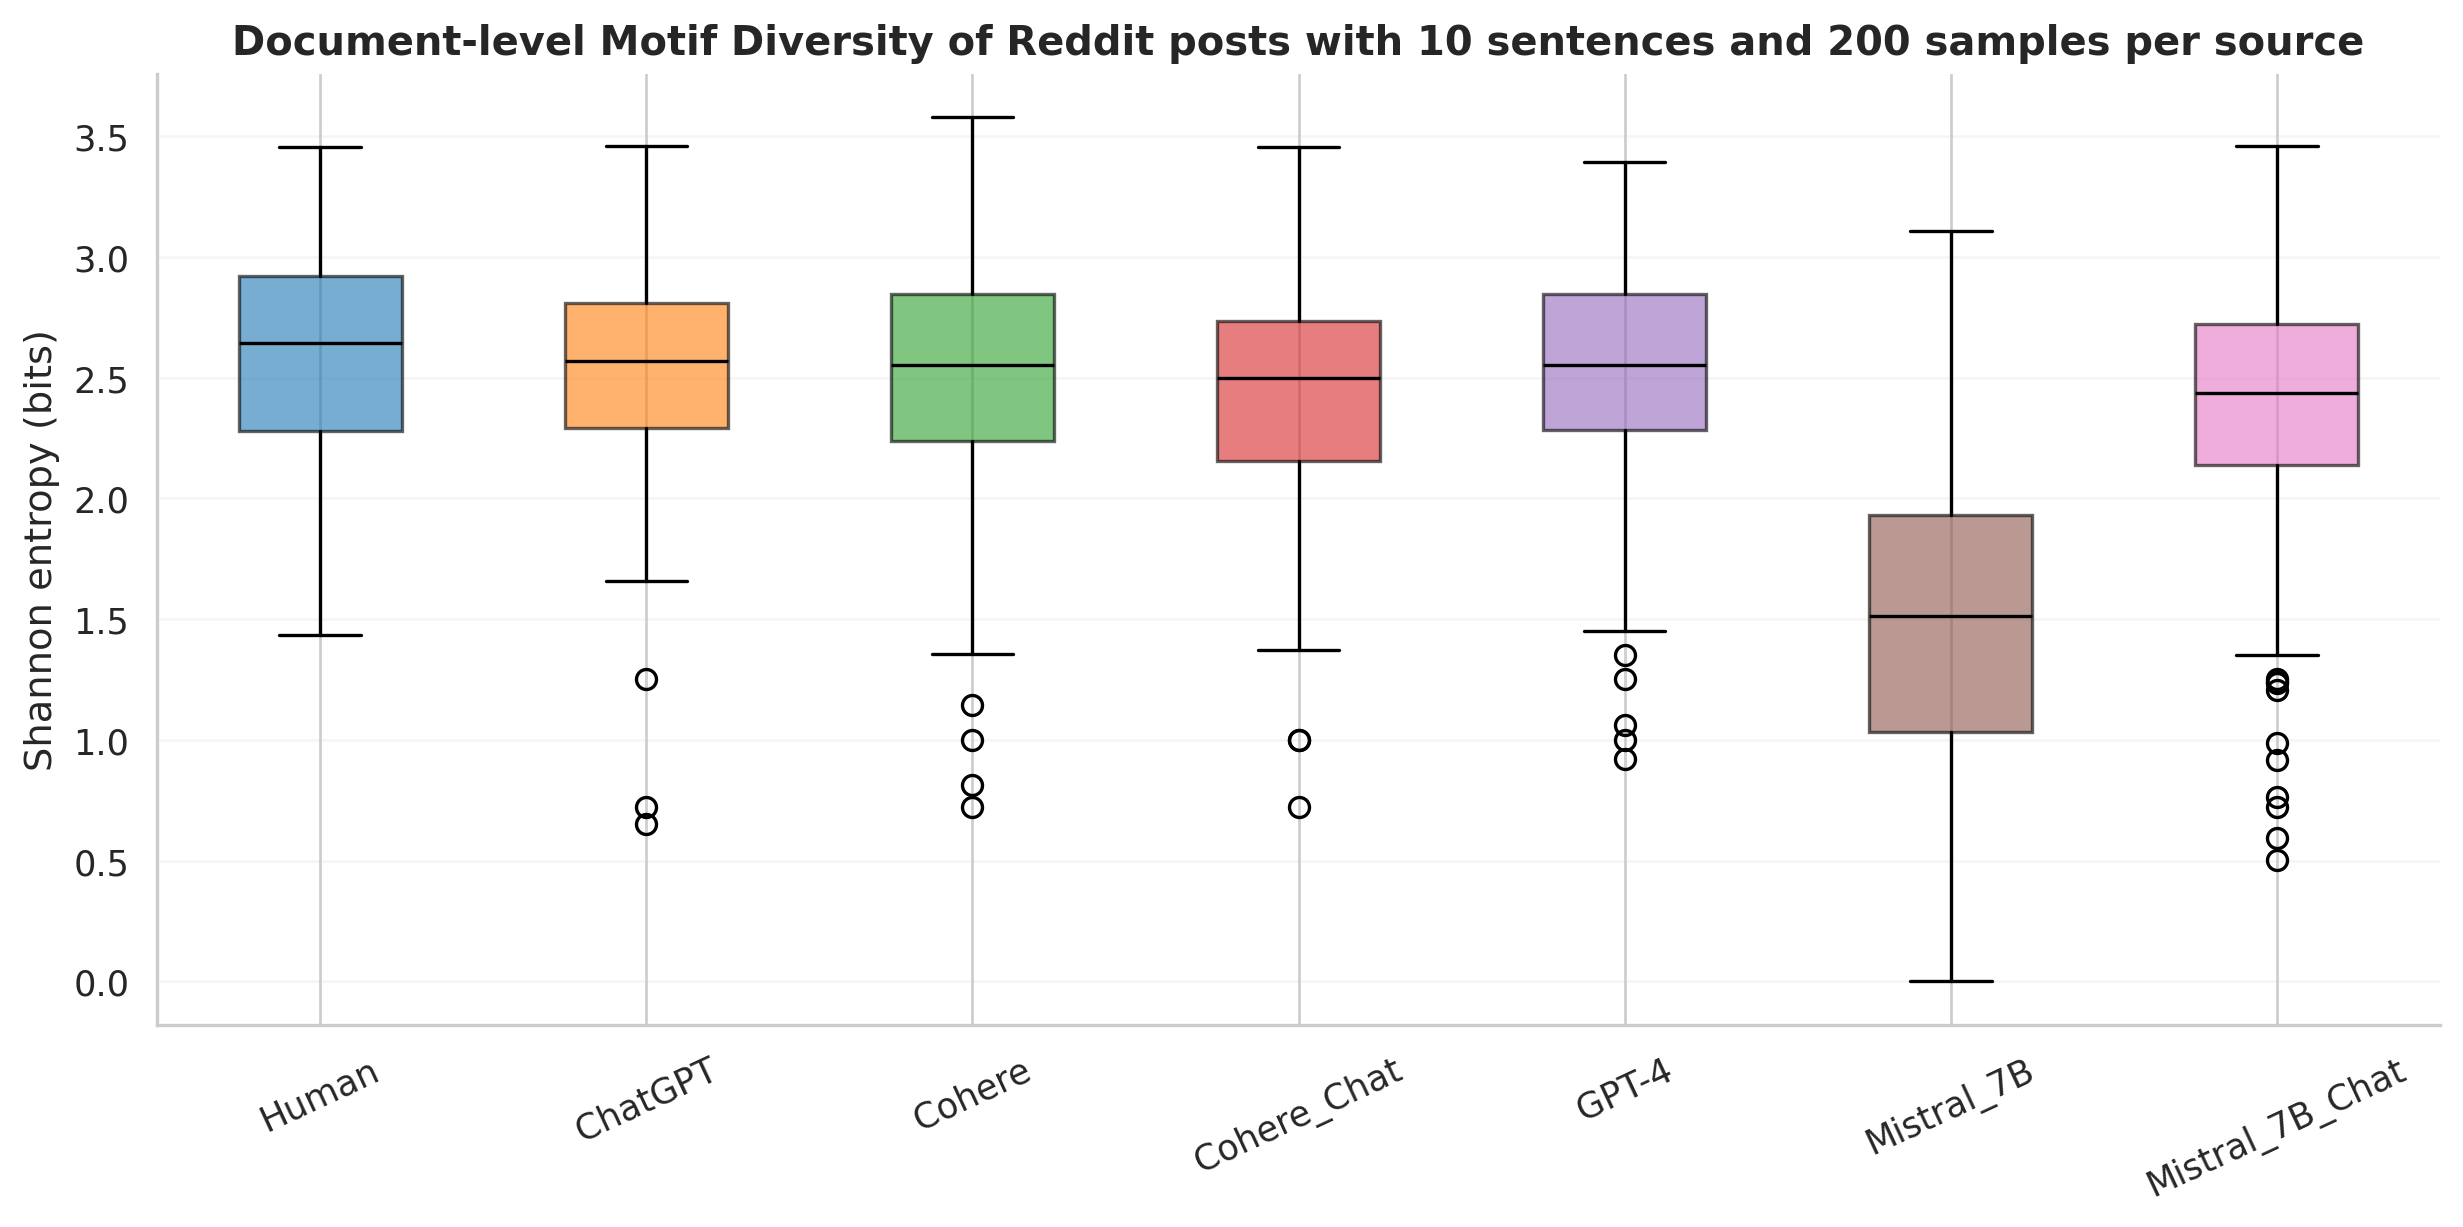

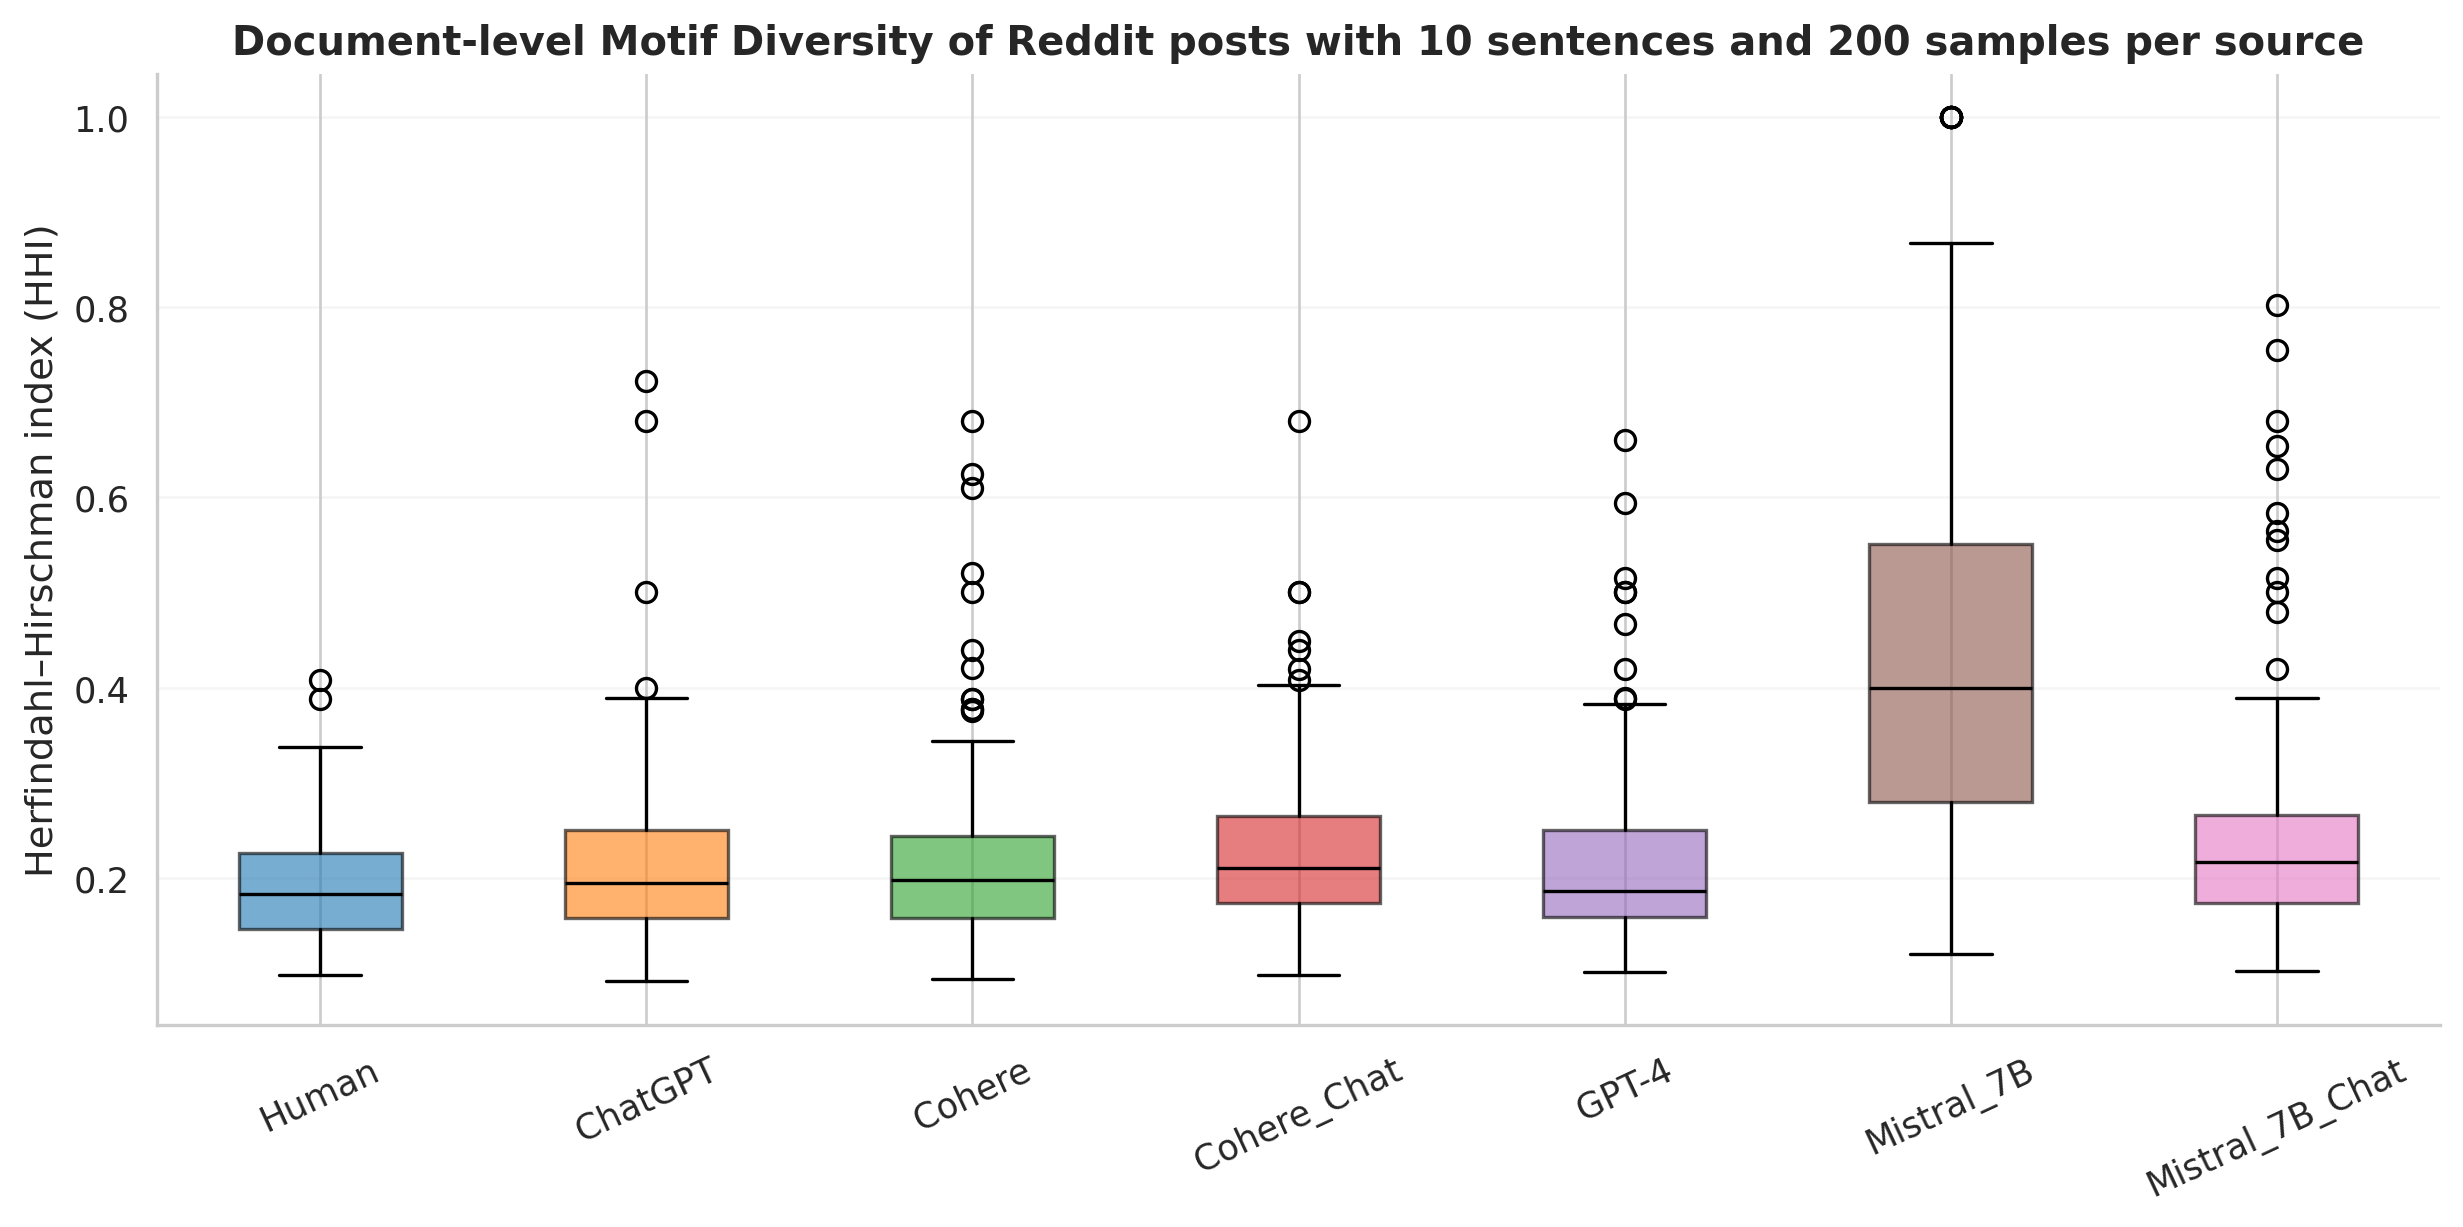

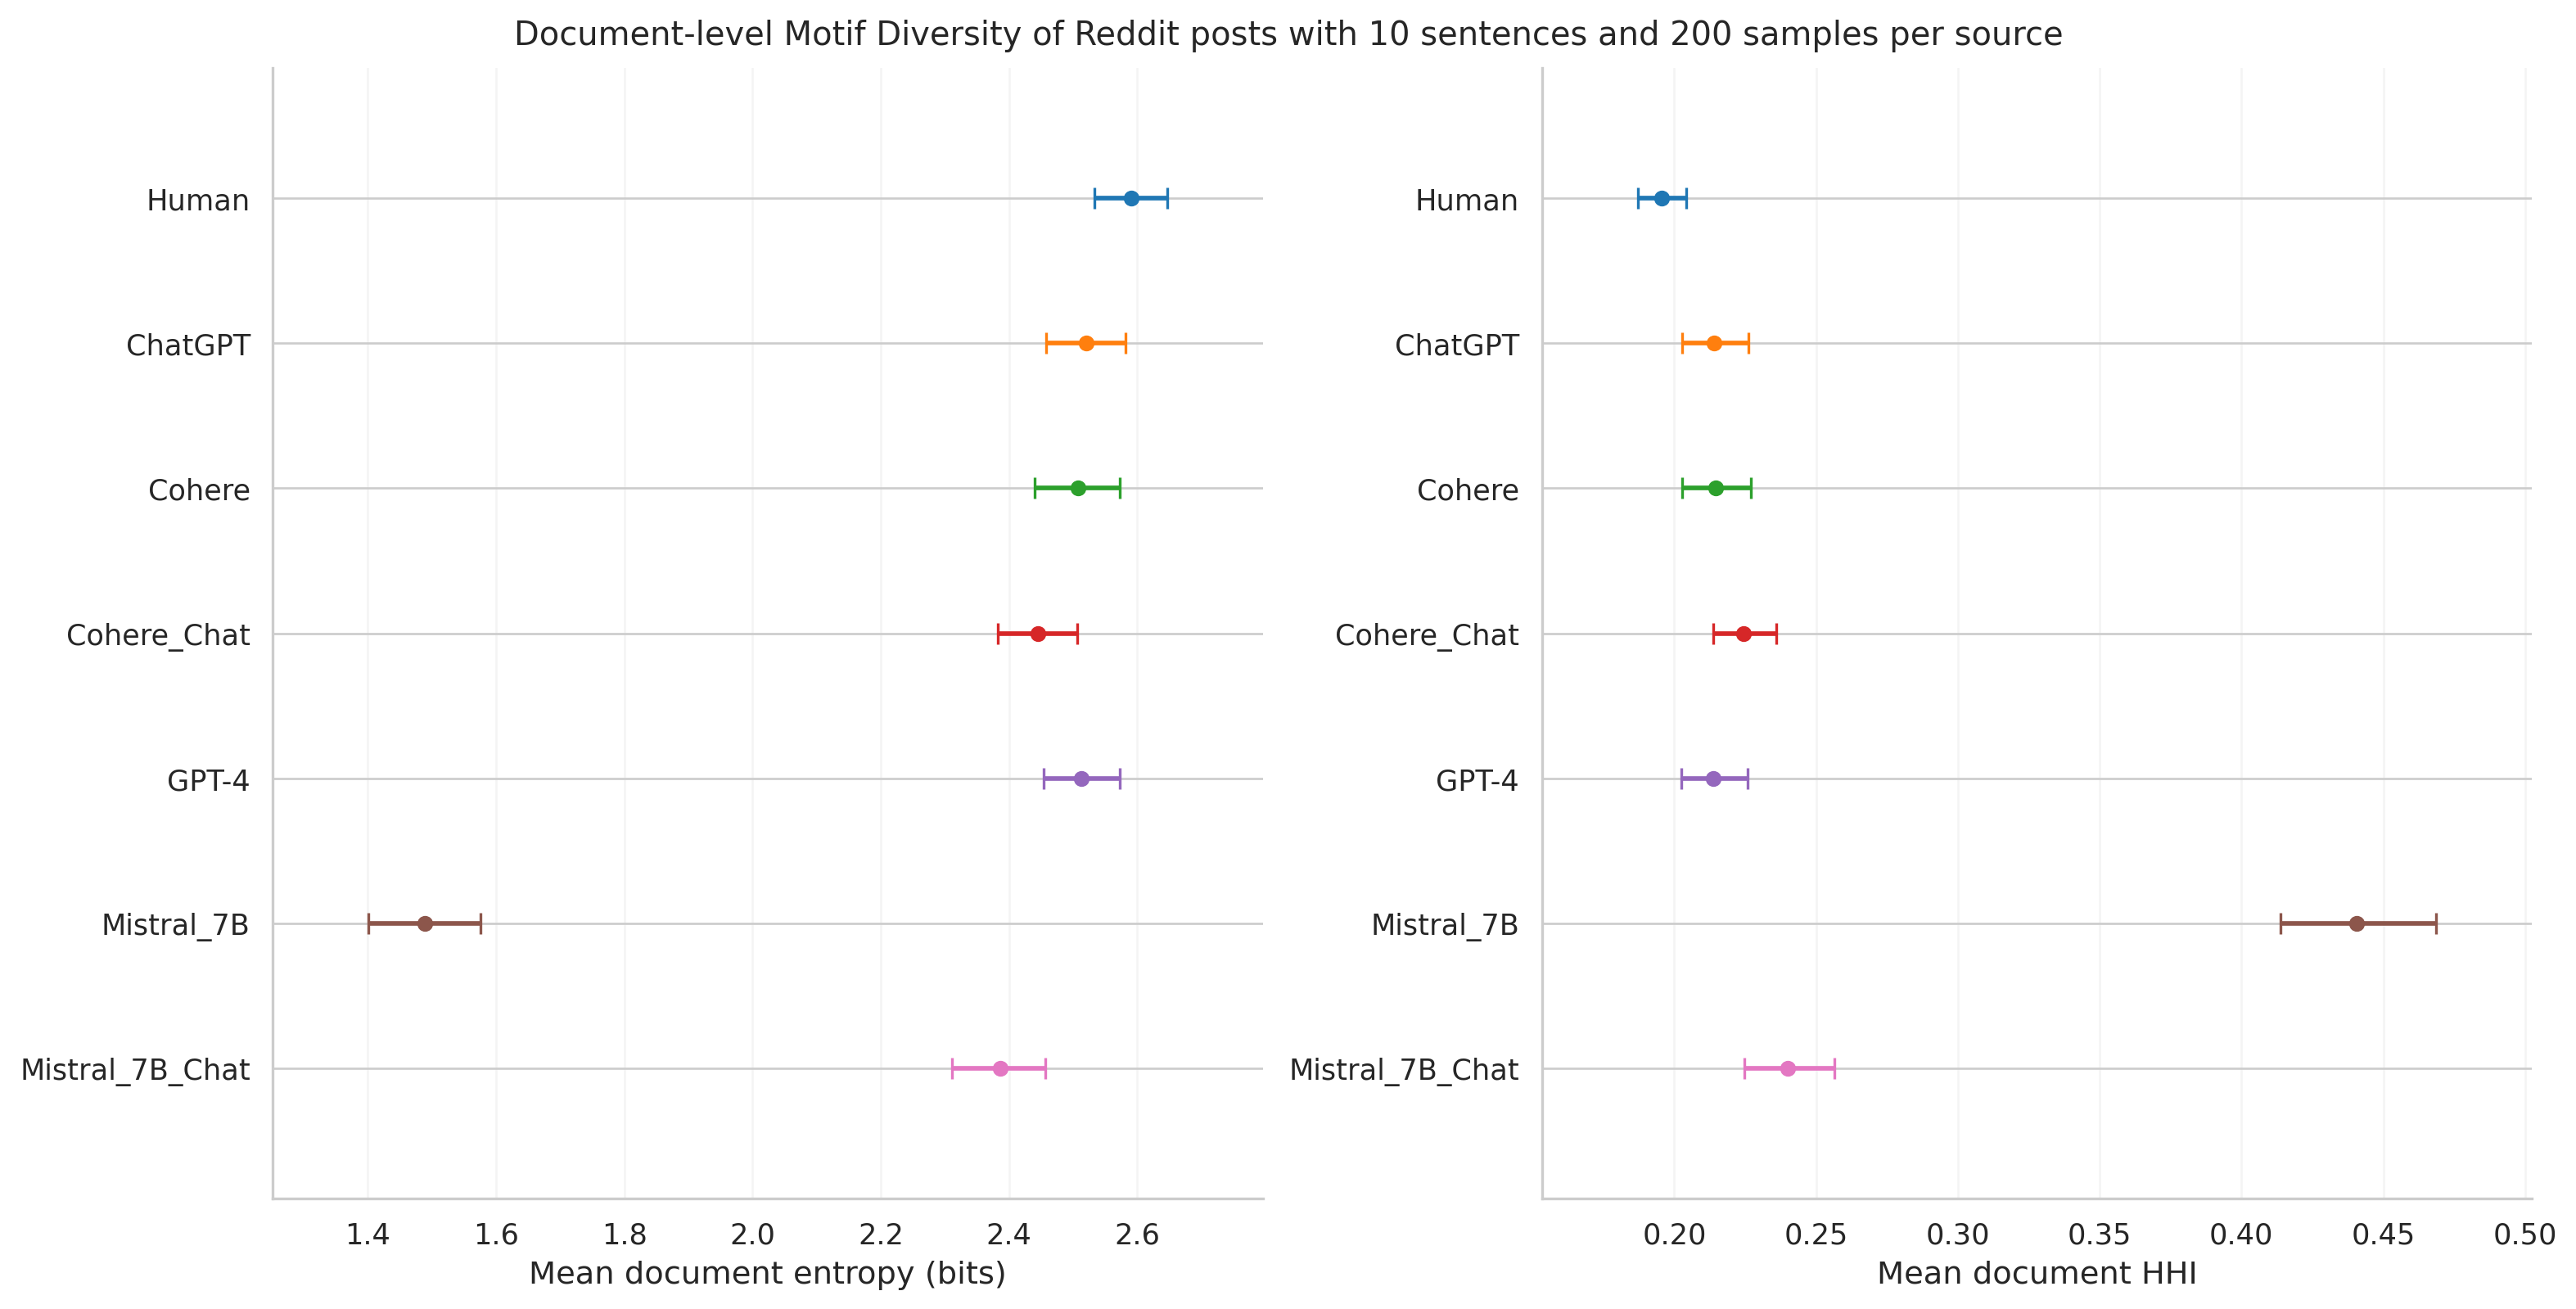

Loaded document-level motif diversity cache: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-reddit__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
Document-level entropy and HHI


,source,metric,n_documents_total,n_documents_valid,n_documents_empty,mean,sd,sem,median,ci_low,ci_high,n_boot,confidence
0,Human,entropy_bits,200,200,0,2.5904,0.4126,0.0292,2.6440,2.5328,2.6471,10000,0.95
1,ChatGPT,entropy_bits,200,200,0,2.5208,0.4495,0.0318,2.5695,2.4583,2.5820,10000,0.95
2,Cohere,entropy_bits,200,200,0,2.5075,0.4742,0.0335,2.5503,2.4398,2.5729,10000,0.95
3,Cohere_Chat,entropy_bits,200,200,0,2.4453,0.4474,0.0316,2.5000,2.3826,2.5068,10000,0.95
4,GPT-4,entropy_bits,200,200,0,2.5136,0.4361,0.0308,2.5503,2.4536,2.5728,10000,0.95
5,Mistral_7B,entropy_bits,200,200,0,1.4887,0.6283,0.0444,1.5138,1.4013,1.5751,10000,0.95
6,Mistral_7B_Chat,entropy_bits,200,200,0,2.3859,0.5237,0.0370,2.4345,2.3116,2.4565,10000,0.95
7,Human,hhi,200,200,0,0.1956,0.0623,0.0044,0.1829,0.1871,0.2043,10000,0.95
8,ChatGPT,hhi,200,200,0,0.2140,0.0839,0.0059,0.1946,0.2026,0.2262,10000,0.95
9,Cohere,hhi,200,200,0,0.2145,0.0887,0.0063,0.1977,0.2028,0.2269,10000,0.95


LLM − Human differences


,source,reference,metric,delta,ci_low,ci_high,excludes_zero,n_boot,confidence
0,ChatGPT,Human,entropy_bits,-0.0696,-0.1547,0.0134,False,10000,0.95
1,Cohere,Human,entropy_bits,-0.0829,-0.1699,0.0040,False,10000,0.95
2,Cohere_Chat,Human,entropy_bits,-0.1451,-0.2298,-0.0592,True,10000,0.95
3,GPT-4,Human,entropy_bits,-0.0768,-0.1578,0.0056,False,10000,0.95
4,Mistral_7B,Human,entropy_bits,-1.1017,-1.2037,-0.9975,True,10000,0.95
5,Mistral_7B_Chat,Human,entropy_bits,-0.2045,-0.2967,-0.1137,True,10000,0.95
6,ChatGPT,Human,hhi,0.0184,0.0040,0.0331,True,10000,0.95
7,Cohere,Human,hhi,0.0189,0.0045,0.0339,True,10000,0.95
8,Cohere_Chat,Human,hhi,0.0289,0.0150,0.0429,True,10000,0.95
9,GPT-4,Human,hhi,0.0182,0.0039,0.0333,True,10000,0.95


In [24]:

# ============================================================
# CELL 09 — Document-level motif diversity
# ============================================================

diversity_dir, diversity_results = (
    diversity_analyzer.analyze_motif_diversity(
        divergence_dir=divergence_dir,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        rebuild=False,
        show=True,
    )
)

print("Document-level entropy and HHI")
display(
    diversity_results["motif_diversity_summary"].round(4)
)

print("LLM − Human differences")
display(
    diversity_results["motif_diversity_deltas"].round(4)
)